## Changes from the original notebook

1. Keep out-of-the-money quotes within five ATM-implied standard deviations of the forward. For each pricing date, estimate ATM implied volatility at $k=0$ by interpolating between the nearest out-of-the-money put and call.
2. Use the revised range of ridge penalty values.

3. Split pricing dates chronologically into 70% train and 30% test, rounded to the nearest whole date.
   Choose the ridge penalty on the training dates using mean daily IV RMSE.
   On each test date, calibrate to that day's quotes and evaluate the same-day fit with the penalty and scales fixed.

# I. Environment and Data Cleaning

In [1]:
from pathlib import Path
from itertools import product
import hashlib
import importlib.metadata
import json
import sys

import numpy as np
import pandas as pd
from scipy.optimize import Bounds, check_grad, minimize
from scipy.special import ndtr
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebook":
    ROOT = ROOT.parent
TABLES = ROOT / "results_1/tables"
FIGURES = ROOT / "results_1/figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
assert TABLES.resolve().is_relative_to(ROOT / "results_1")
assert FIGURES.resolve().is_relative_to(ROOT / "results_1")
plt.rcParams.update({"font.size": 9, "axes.grid": True, "grid.alpha": .2, "figure.dpi": 110})
COLORS = {"baseline": "#245a9a", "ridge": "#c45a22"}


def export(name, frame):
    """All numerical exports share one fixed, protected destination."""
    assert Path(name).name == name and name.endswith(".csv")
    frame.to_csv(TABLES / name, index=False, date_format="%Y-%m-%d", float_format="%.17g")


def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / (name + ".png"), dpi=200, bbox_inches="tight")
    display(fig)
    plt.close(fig)

In [2]:

# Load the original datasets
option_source = pd.read_csv(ROOT / "data/options_data.csv")
future_source = pd.read_csv(ROOT / "data/spx_futures.csv")

options = option_source.copy()
futures = future_source.copy()


# Check required columns
option_key = ["pricedate", "Expiry", "strike", "option_type"]

required_option_columns = option_key + ["impliedvol"]
required_future_columns = ["query_date", "ID", "fut_last_trade_dt()", "px_last(dates=#dt)"]

assert set(required_option_columns).issubset(options.columns)
assert set(required_future_columns).issubset(futures.columns)

In [3]:
# Convert dates and numerical columns
for column in ["pricedate", "Expiry"]:
    options[column] = pd.to_datetime(options[column], format="%d/%m/%Y", errors="raise")

for column in ["query_date", "fut_last_trade_dt()"]:
    futures[column] = pd.to_datetime(futures[column], format="%Y-%m-%d", errors="raise")

for column in ["strike", "impliedvol"]:
    options[column] = pd.to_numeric(options[column], errors="raise")

futures["px_last(dates=#dt)"] = pd.to_numeric(
    futures["px_last(dates=#dt)"], errors="raise"
)

options["source_record"] = np.arange(1, len(options) + 1)
options["iv_decimal"] = options["impliedvol"] / 100

In [4]:
# Validate the original data
assert options[option_key].notna().all().all()
assert not options.duplicated(option_key).any()
assert not futures.duplicated(["query_date", "ID"]).any()

assert options["option_type"].isin(["Call", "Put"]).all()
assert np.isfinite(options["strike"]).all()
assert (options["strike"] > 0).all()
assert (options["Expiry"] > options["pricedate"]).all()

reported_iv = options["impliedvol"].dropna()
reported_forward = futures["px_last(dates=#dt)"].dropna()

assert np.isfinite(reported_iv).all()
assert (reported_iv > 0).all()

assert np.isfinite(reported_forward).all()
assert (reported_forward > 0).all()

In [5]:
# Remove observations with missing IV
missing_iv = options["impliedvol"].isna()

clean = options.loc[~missing_iv].copy().reset_index(drop=True)
excluded = options.loc[missing_iv].copy()

excluded["exclusion_reason"] = "missing_impliedvol"

ledger = options.copy()
ledger["cleaning_status"] = np.where(
    missing_iv, "missing_impliedvol", "retained"
)


In [6]:
# Verify cleaning results
assert len(options) == 44234
assert len(excluded) == 2074
assert len(clean) == 42160
assert clean["pricedate"].nunique() == 103

assert set(clean["source_record"]).isdisjoint(excluded["source_record"])

all_records = pd.concat([
    clean["source_record"],
    excluded["source_record"]
])

assert sorted(all_records) == list(options["source_record"])

assert options["Expiry"].nunique() == 1
assert options["Expiry"].iloc[0] == pd.Timestamp("2026-12-18")

In [7]:
# Calculate option data coverage
coverage = (
    options.groupby(["pricedate", "option_type"])["impliedvol"]
    .agg(rows="size", nonmissing="count")
    .reset_index()
)

coverage["missing"] = coverage["rows"] - coverage["nonmissing"]

In [8]:
# Record source schemas
schema_rows = []

datasets = [
    ("options", option_source, options),
    ("futures", future_source, futures)
]

for name, original, parsed in datasets:
    for column in original.columns:
        schema_rows.append({
            "dataset": name,
            "column": column,
            "source_dtype": str(original[column].dtype),
            "parsed_dtype": str(parsed[column].dtype),
            "missing_count": int(parsed[column].isna().sum())
        })

schema = pd.DataFrame(schema_rows)

# Record input file information and hashes
input_rows = []

input_files = [
    ("data/options_data.csv", options),
    ("data/spx_futures.csv", futures)
]

for filename, frame in input_files:
    path = ROOT / filename

    input_rows.append({
        "path": filename,
        "rows": len(frame),
        "sha256": hashlib.sha256(path.read_bytes()).hexdigest()
    })

inputs = pd.DataFrame(input_rows)



# Record Python and library versions
environment_rows = [
    {"component": "python", "version": sys.version.split()[0]}
]

packages = ["numpy", "pandas", "scipy", "matplotlib", "nbclient", "nbformat"]

for package in packages:
    try:
        version = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        version = "not installed"

    environment_rows.append({
        "component": package,
        "version": version
    })

environment = pd.DataFrame(environment_rows)

display(environment)


# Record source integrity checks
integrity_checks = [
    ("option_duplicate_keys", options.duplicated(option_key).sum()),
    ("futures_duplicate_keys", futures.duplicated(["query_date", "ID"]).sum()),
    ("option_nonpositive_strikes", (options["strike"] <= 0).sum()),
    ("option_nonpositive_reported_iv", (reported_iv <= 0).sum()),
    ("option_nonfinite_reported_iv", (~np.isfinite(reported_iv)).sum()),
    ("option_expired_on_pricing_date", (options["Expiry"] <= options["pricedate"]).sum()),
    ("futures_nonpositive_reported_last", (reported_forward <= 0).sum()),
    ("futures_nonfinite_reported_last", (~np.isfinite(reported_forward)).sum())
]

source_integrity = pd.DataFrame(
    integrity_checks,
    columns=["check", "invalid_count"]
)

source_integrity["invalid_count"] = source_integrity["invalid_count"].astype(int)

,component,version
0,python,3.12.14
1,numpy,2.3.5
2,pandas,2.2.3
3,scipy,1.17.0
4,matplotlib,3.10.8
5,nbclient,not installed
6,nbformat,not installed


In [9]:
# Calculate futures data coverage
futures_coverage = (
    futures.groupby("ID")
    .agg(
        rows=("query_date", "size"),
        dates=("query_date", "nunique"),
        first_date=("query_date", "min"),
        last_date=("query_date", "max"),
        nonmissing_last=("px_last(dates=#dt)", "count")
    )
    .reset_index()
)

futures_coverage["missing_last"] = (
    futures_coverage["rows"] - futures_coverage["nonmissing_last"]
)

In [10]:
# Export all results
export("source_ledger.csv", ledger)
export("excluded_missing_iv.csv", excluded)
export("cleaned_options.csv", clean)
export("source_schema.csv", schema)
export("data_coverage.csv", coverage)
export("input_manifest.csv", inputs)
export("environment.csv", environment)
export("source_integrity.csv", source_integrity)
export("futures_coverage.csv", futures_coverage)


# Display the cleaning summary
summary = pd.DataFrame({
    "source_rows": [len(options)],
    "missing_IV": [len(excluded)],
    "retained": [len(clean)]
})

display(summary)


,source_rows,missing_IV,retained
0,44234,2074,42160


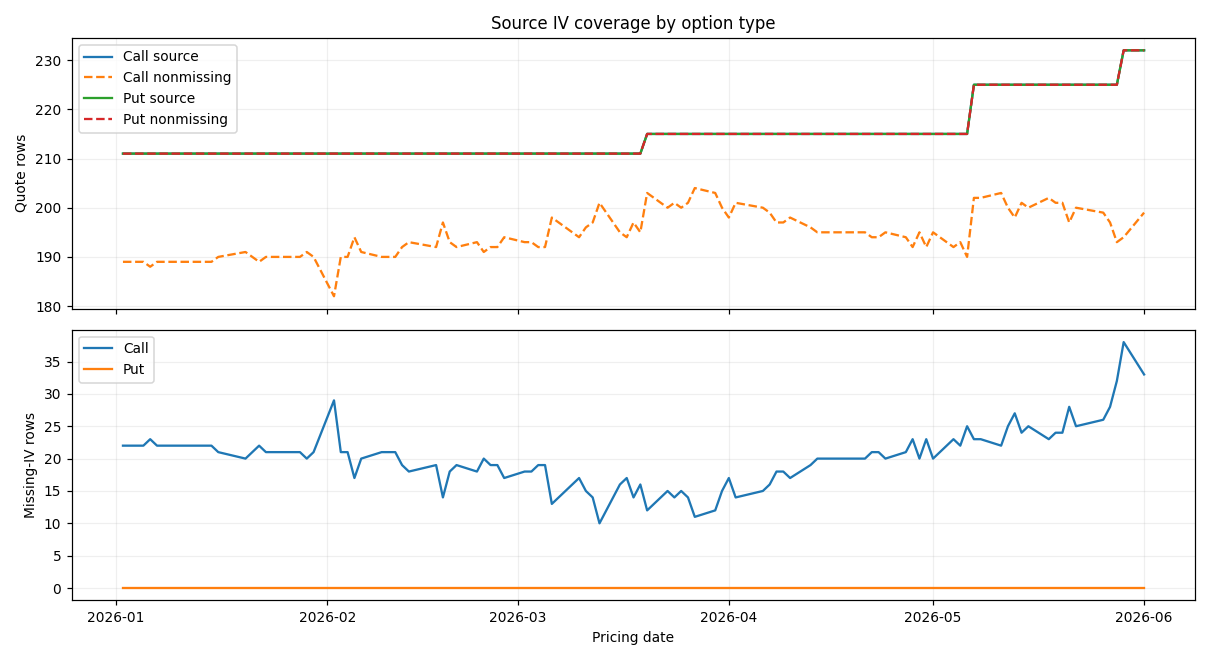

In [11]:
# Create two plots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

# Plot calls and puts
for option_type in ["Call", "Put"]:
    data = coverage[coverage["option_type"] == option_type]

    ax1.plot(data["pricedate"], data["rows"], label=option_type + " source")
    ax1.plot(data["pricedate"], data["nonmissing"], "--",
             label=option_type + " nonmissing")

    ax2.plot(data["pricedate"], data["missing"], label=option_type)

# Add titles and labels
ax1.set_title("Source IV coverage by option type")
ax1.set_ylabel("Quote rows")
ax1.legend()

ax2.set_xlabel("Pricing date")
ax2.set_ylabel("Missing-IV rows")
ax2.legend()

# Save and display
save_figure(fig, "01_data_coverage")


# II. Calibration Setup

## 1. Log Moneyness and Total Implied Variance

In [12]:
# Select ESZ26 futures prices

forward = futures[futures["ID"] == "ESZ26 Index"].copy()
forward = forward[["query_date", "px_last(dates=#dt)"]]
forward = forward.rename(columns={
    "query_date": "forward_date",
    "px_last(dates=#dt)": "F"
})

assert len(forward) > 0
assert not forward["forward_date"].duplicated().any()

# Match futures prices to options
quotes = pd.merge(
    clean,
    forward,
    left_on="pricedate",
    right_on="forward_date",
    how="left",
    validate="many_to_one"
)

assert len(quotes) == len(clean)
assert quotes["source_record"].tolist() == clean["source_record"].tolist()
assert (quotes["forward_date"] == quotes["pricedate"]).all()
assert np.isfinite(quotes["F"]).all()
assert (quotes["F"] > 0).all()


# Calculate time to maturity
quotes["maturity_days"] = (quotes["Expiry"] - quotes["pricedate"]).dt.days
quotes["T"] = quotes["maturity_days"] / 365
assert np.isfinite(quotes["T"]).all()
assert (quotes["T"] > 0).all()


# Record forward prices and maturities
forward_audit = quotes.groupby("pricedate").agg(
    rows=("source_record", "size"),
    F=("F", "first"),
    maturity_days=("maturity_days", "first"),
    T=("T", "first")
).reset_index()

export("forward_maturity_by_date.csv", forward_audit)

In [13]:
# Calculate log-moneyness and total implied variance
quotes["k"] = np.log(quotes["strike"] / quotes["F"])
quotes["w_market"] = quotes["iv_decimal"] ** 2 * quotes["T"]

assert np.isfinite(quotes["k"]).all()
assert np.isfinite(quotes["w_market"]).all()
assert (quotes["w_market"] > 0).all()


# Verify the calculations
np.testing.assert_allclose(
    quotes["F"] * np.exp(quotes["k"]),
    quotes["strike"],
    rtol=1e-12,
    atol=0
)

np.testing.assert_allclose(
    np.sqrt(quotes["w_market"] / quotes["T"]),
    quotes["iv_decimal"],
    rtol=1e-12,
    atol=0
)

# Identify out-of-the-money options
otm_put = (
    (quotes["option_type"] == "Put") &
    (quotes["strike"] < quotes["F"])
)

otm_call = (
    (quotes["option_type"] == "Call") &
    (quotes["strike"] > quotes["F"])
)

quotes["selected"] = otm_put | otm_call

quotes["selection_reason"] = "non_otm_side"

quotes.loc[otm_put, "selection_reason"] = "otm_put"
quotes.loc[otm_call, "selection_reason"] = "otm_call"

quotes.loc[
    quotes["strike"] == quotes["F"],
    "selection_reason"
] = "exact_forward"

In [14]:
# Create the calibration sample
sample = quotes[quotes["selected"]].copy()

sample = sample.sort_values(
    ["pricedate", "k", "source_record"],
    kind="stable"
).reset_index(drop=True)

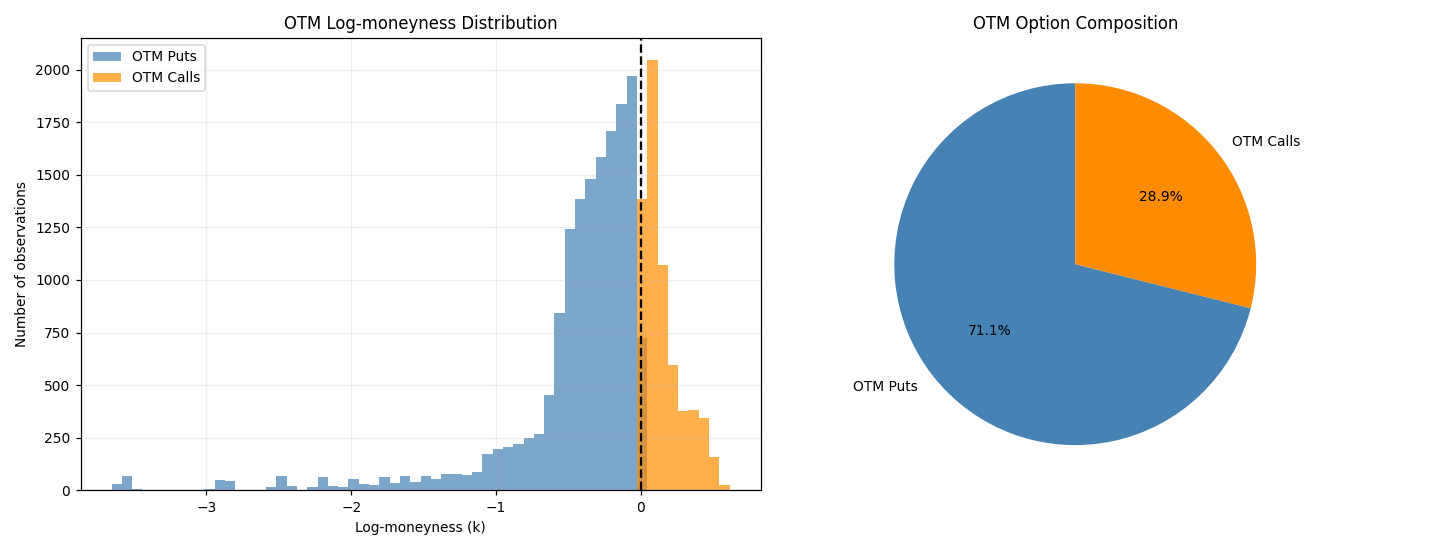

Minimum observed k: -3.6557749984658954
Maximum observed k: 0.6155690459145706
OTM puts: 15722
OTM calls: 6394
Total selected: 22116


In [15]:
# Plot OTM log-moneyness distribution and option composition
puts = sample.loc[sample["selection_reason"] == "otm_put", "k"]
calls = sample.loc[sample["selection_reason"] == "otm_call", "k"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Distribution of log-moneyness
bins = np.linspace(sample["k"].min(), sample["k"].max(), 61)

axes[0].hist(puts, bins=bins, color="steelblue",
             alpha=0.7, label="OTM Puts")
axes[0].hist(calls, bins=bins, color="darkorange",
             alpha=0.7, label="OTM Calls")

axes[0].axvline(0, color="black", linestyle="--")
axes[0].set_xlabel("Log-moneyness (k)")
axes[0].set_ylabel("Number of observations")
axes[0].set_title("OTM Log-moneyness Distribution")
axes[0].legend()

# 2. Put vs call composition
axes[1].pie(
    [len(puts), len(calls)],
    labels=["OTM Puts", "OTM Calls"],
    colors=["steelblue", "darkorange"],
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("OTM Option Composition")

plt.tight_layout()
plt.show()

print("Minimum observed k:", sample["k"].min())
print("Maximum observed k:", sample["k"].max())
print("OTM puts:", len(puts))
print("OTM calls:", len(calls))
print("Total selected:", len(sample))

In [16]:
def atm_volatility(day):
    put = day.loc[day["k"].lt(0)].nlargest(1, "k").iloc[0]
    call = day.loc[day["k"].gt(0)].nsmallest(1, "k").iloc[0]
    return np.interp(
        0.0, [put["k"], call["k"]], [put["iv_decimal"], call["iv_decimal"]]
    )


atm_iv_by_date = sample.groupby("pricedate")[["k", "iv_decimal"]].apply(atm_volatility)
cutoff = 5.0 * sample["pricedate"].map(atm_iv_by_date) * np.sqrt(sample["T"])
keep = sample["k"].abs().le(cutoff)

outliers = sample.loc[~keep].copy()
sample = sample.loc[keep].copy()
print(f"Excluded {len(outliers):,} quotes. Retained {len(sample):,}.")

Excluded 2,241 quotes. Retained 19,875.


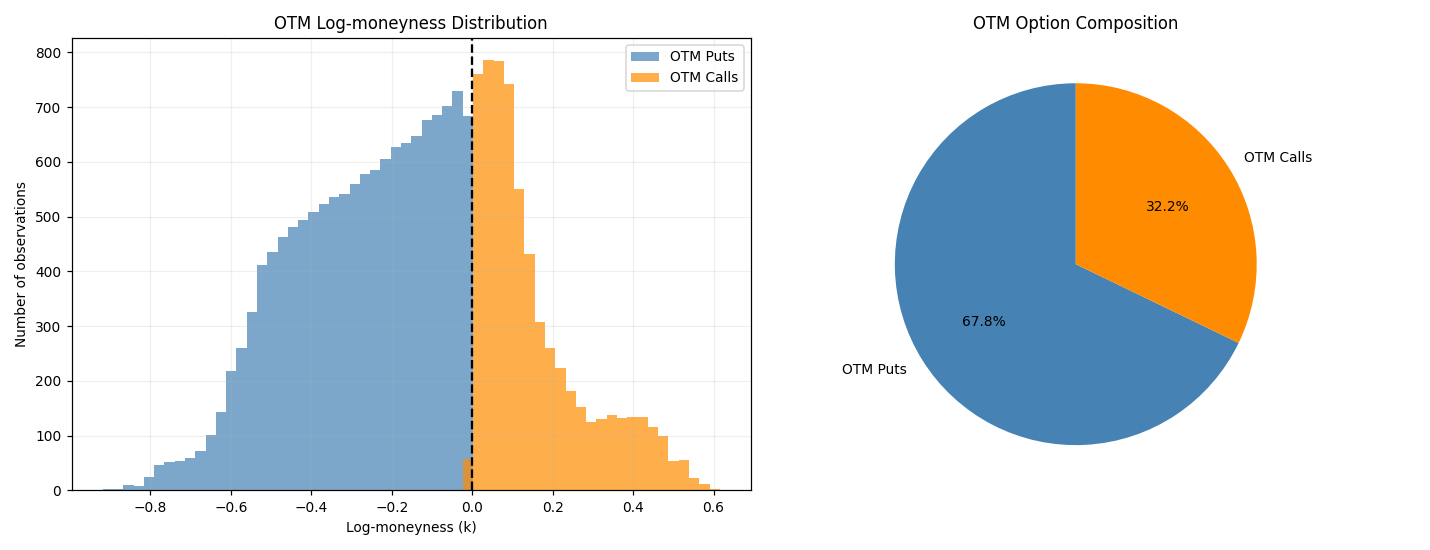

Minimum observed k: -0.9184422618266054
Maximum observed k: 0.6155690459145706
OTM puts: 13481
OTM calls: 6394
Total selected: 19875


In [17]:
# Plot OTM log-moneyness distribution and option composition
puts = sample.loc[sample["selection_reason"] == "otm_put", "k"]
calls = sample.loc[sample["selection_reason"] == "otm_call", "k"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Distribution of log-moneyness
bins = np.linspace(sample["k"].min(), sample["k"].max(), 61)

axes[0].hist(puts, bins=bins, color="steelblue",
             alpha=0.7, label="OTM Puts")
axes[0].hist(calls, bins=bins, color="darkorange",
             alpha=0.7, label="OTM Calls")

axes[0].axvline(0, color="black", linestyle="--")
axes[0].set_xlabel("Log-moneyness (k)")
axes[0].set_ylabel("Number of observations")
axes[0].set_title("OTM Log-moneyness Distribution")
axes[0].legend()

# 2. Put vs call composition
axes[1].pie(
    [len(puts), len(calls)],
    labels=["OTM Puts", "OTM Calls"],
    colors=["steelblue", "darkorange"],
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("OTM Option Composition")

plt.tight_layout()
plt.show()

print("Minimum observed k:", sample["k"].min())
print("Maximum observed k:", sample["k"].max())
print("OTM puts:", len(puts))
print("OTM calls:", len(calls))
print("Total selected:", len(sample))

In [18]:
# Organize observations by pricing date
days = sorted(sample["pricedate"].unique())

daily_inputs = {}

for date, data in sample.groupby("pricedate", sort=True):
    daily_inputs[date] = data


# Calculate calibration coverage
calibration_coverage = (
    sample.groupby(["pricedate", "option_type"])
    .size()
    .reset_index(name="rows")
)

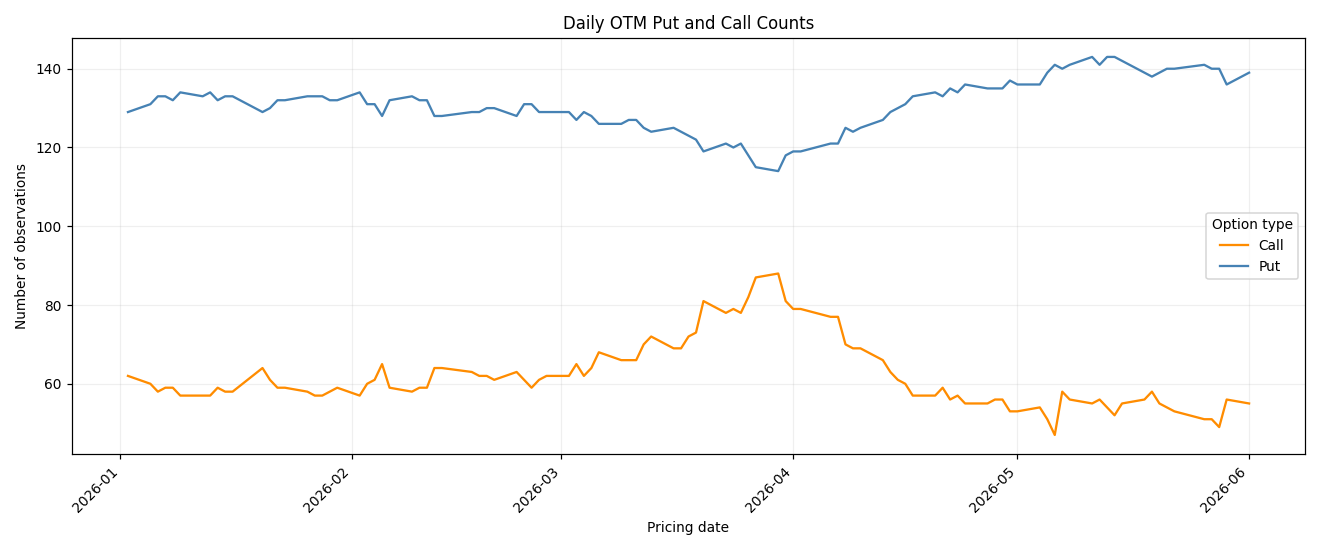

Number of pricing dates: 103


In [19]:
# Plot daily OTM put and call counts
coverage_plot = (
    calibration_coverage
    .pivot(index="pricedate", columns="option_type", values="rows")
    .fillna(0)
    .sort_index()
)

ax = coverage_plot.plot(
    figsize=(12, 5),
    color=["darkorange", "steelblue"],
    linewidth=1.5
)

ax.set_xlabel("Pricing date")
ax.set_ylabel("Number of observations")
ax.set_title("Daily OTM Put and Call Counts")
ax.legend(title="Option type")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Number of pricing dates:", len(days))

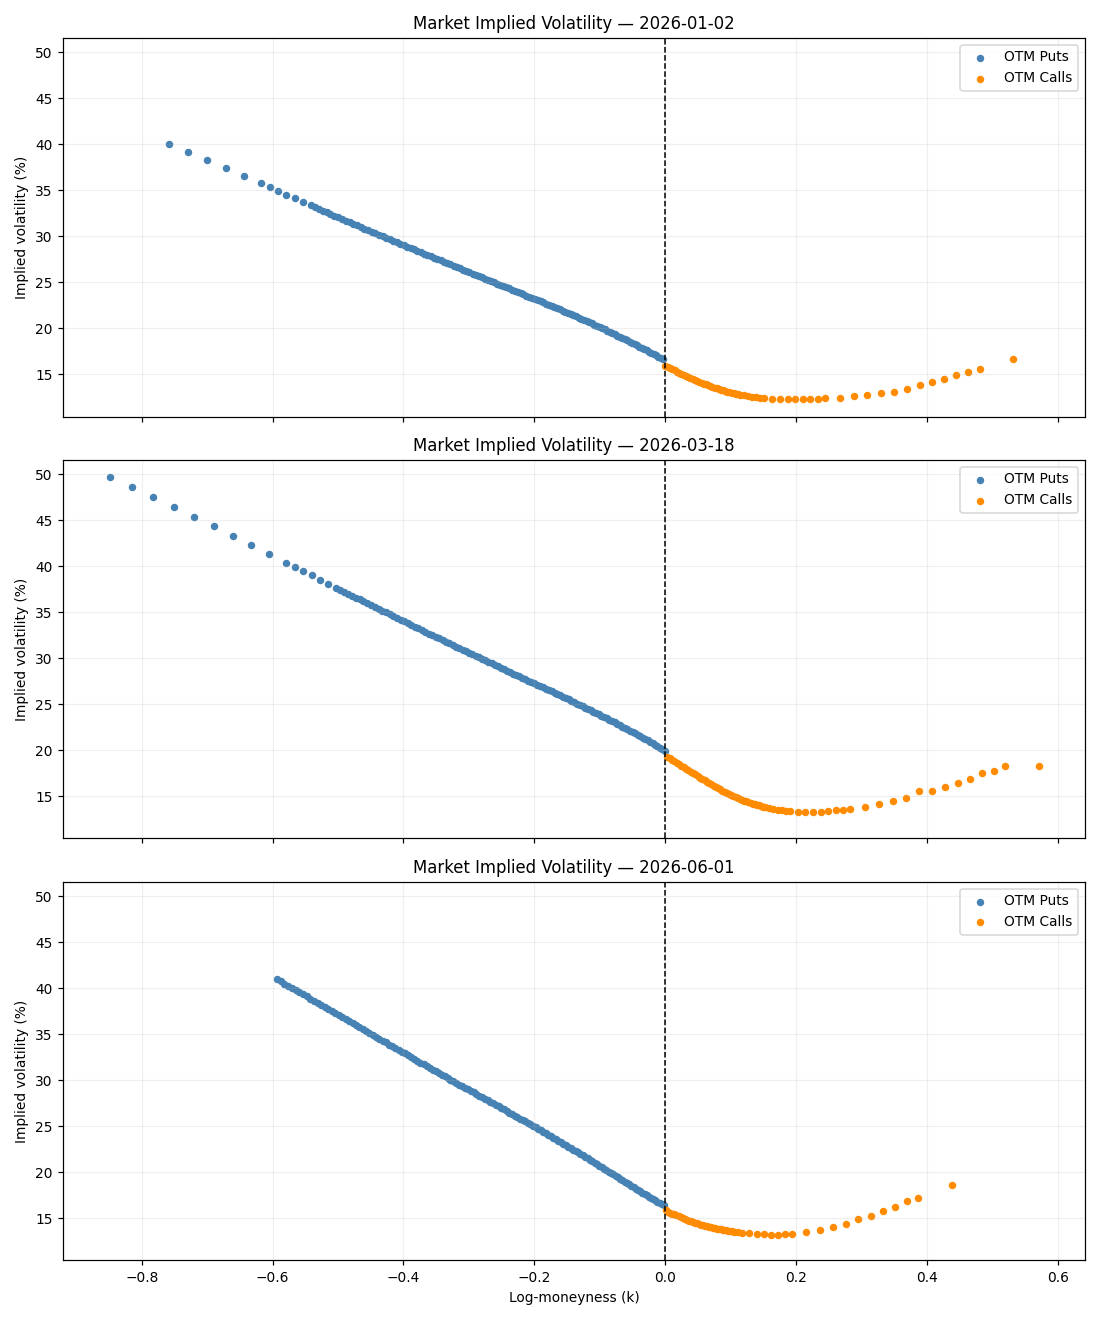

In [20]:
# Plot market implied volatility for the first, middle, and last dates
selected_days = [days[0], days[len(days)//2], days[-1]]

fig, axes = plt.subplots(3, 1, figsize=(10, 12), sharex=True, sharey=True)

for ax, date in zip(axes, selected_days):
    data = daily_inputs[date]

    puts = data[data["option_type"] == "Put"]
    calls = data[data["option_type"] == "Call"]

    ax.scatter(puts["k"], puts["iv_decimal"] * 100,
               color="steelblue", s=15, label="OTM Puts")

    ax.scatter(calls["k"], calls["iv_decimal"] * 100,
               color="darkorange", s=15, label="OTM Calls")

    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set_ylabel("Implied volatility (%)")
    ax.set_title(f"Market Implied Volatility — {date:%Y-%m-%d}")
    ax.legend()

axes[-1].set_xlabel("Log-moneyness (k)")

plt.tight_layout()
plt.show()

## 2. Parameter Settings

In [21]:
# SVI parameters and optimizer settings
RAW = ["a", "b", "rho", "m", "s"]
COORD = ["q_v", "q_b", "q_r", "q_m", "q_ell"]

# L-BFGS-B settings
METHOD = "L-BFGS-B"
SOLVER = {
    "ftol": 1e-12,
    "gtol": 1e-8,
    "maxiter": 2000,
    "maxfun": 20000,
    "maxls": 50,
    "maxcor": 10
}
BOUNDS = Bounds(
    [0, 0, -np.inf, -np.inf, -np.inf],
    [np.inf, np.inf, np.inf, np.inf, np.inf]
)

# Multistart settings
RHO_STARTS = [-0.8, 0, 0.8]
S_STARTS = [0.05, 0.2, 1]


Add parameters here

In [22]:

# Calculate SVI total implied variance
def svi(k, theta):
    a, b, rho, m, s = theta
    x = np.asarray(k, dtype=float) - m
    return a + b * (rho*x + np.hypot(x, s))


# Calculate minimum SVI variance
def minimum_variance(theta):
    a, b, rho, m, s = theta
    return float(a + b*s*np.sqrt(1-rho**2))


# Convert optimizer coordinates to SVI parameters
def to_raw(q):
    q = np.asarray(q, dtype=float)
    if q.shape != (5,) or not np.isfinite(q).all() or (q[:2] < 0).any():
        raise ValueError("Require finite q and nonnegative v,b")

    v, b, r, m, ell = q
    with np.errstate(over="raise", invalid="raise", under="ignore"):
        rho, s = np.tanh(r), np.exp(ell)
        a = v - b*s*np.sqrt(1-rho**2)

    theta = np.array([a, b, rho, m, s])
    if not feasible(theta):
        raise ValueError("Mapped parameters are outside the representable SVI domain")
    return theta


# Convert SVI parameters to optimizer coordinates
def to_coordinates(theta):
    if not feasible(theta):
        raise ValueError("Infeasible raw parameters")

    a, b, rho, m, s = theta
    return np.array([minimum_variance(theta), b, np.arctanh(rho), m, np.log(s)])


# Calculate fitting loss and analytical gradient
def loss_gradient(q, k, market_w):
    a, b, rho, m, s = to_raw(q)

    with np.errstate(over="raise", invalid="raise", divide="raise"):
        x, c = k-m, np.sqrt(1-rho**2)
        h = np.hypot(x, s)
        residual = svi(k, [a,b,rho,m,s]) - market_w

        jacobian = np.column_stack([
            np.ones_like(k),
            rho*x+h-s*c,
            b*(c**2*x+s*rho*c),
            -b*(rho+x/h),
            b*s*(s/h-c)
        ])

        loss = float(np.mean(residual**2))
        gradient = (2.0/k.size) * (jacobian.T @ residual)

    if not np.isfinite(loss) or not np.isfinite(gradient).all():
        raise FloatingPointError("Nonfinite loss or gradient")

    return loss, gradient

In [23]:
# Check whether SVI parameters are valid
def feasible(theta):
    if not np.isfinite(theta).all():
        return False

    a, b, rho, m, s = theta

    if b < 0 or not -1 < rho < 1 or s <= 0:
        return False

    with np.errstate(over="ignore", invalid="ignore"):
        v = minimum_variance(theta)

    return bool(np.isfinite(v) and v >= 0)

# Create synthetic data for mathematical checks
synthetic_k = np.array([-1.0, -0.25, 0.0, 0.1, 0.6])
synthetic_w = 0.02 + 0.03 * synthetic_k**2
cases = {
    "interior": [0.01, 0.1, -0.5, 0.0, np.log(0.2)],
    "zero_minimum": [0.0, 0.1, 0.5, -0.1, np.log(0.2)],
    "b_zero": [0.01, 0.0, -0.5, 1.5, np.log(0.2)],
    "both_zero": [0.0, 0.0, 0.8, -0.4, np.log(0.15)],
    "interior_second": [0.02, 0.3, 2.0, 0.2, np.log(0.8)]
}

# Check parameter conversion, minimum variance, and gradient
math_checks = []
for name, values in cases.items():
    q = np.array(values)
    theta = to_raw(q)

    # Check conversion back to optimizer coordinates
    recovered_q = to_coordinates(theta)
    np.testing.assert_allclose(recovered_q, q, rtol=1e-12, atol=1e-14)

    # Check minimum total variance
    a, b, rho, m, s = theta
    k_min = m - rho * s / np.sqrt(1 - rho**2)
    np.testing.assert_allclose(svi(k_min, theta), q[0], rtol=1e-12, atol=1e-14)

    # Check that b = 0 produces a constant curve
    if b == 0:
        expected_w = np.full(5, q[0])
        np.testing.assert_array_equal(svi(synthetic_k, theta), expected_w)

    # Compare analytical and numerical gradients
    def loss_only(q):
        return loss_gradient(q, synthetic_k, synthetic_w)[0]
    def gradient_only(q):
        return loss_gradient(q, synthetic_k, synthetic_w)[1]
    error = check_grad(loss_only, gradient_only, q, epsilon=1e-7)
    assert error <= 1e-6
    math_checks.append({
        "check": name,
        "error": error,
        "tolerance": 1e-6,
        "passed": True
    })

# Check that invalid parameter inputs are rejected
invalid_cases = [
    [-1, 0.1, 0, 0, 0],
    [0.01, -0.1, 0, 0, 0],
    [0.01, 0.1, 1000, 0, 0],
    [0.01, 0.1, 0, 0, 1000],
    [0.01, 0.1, 0, 0, -1000]
]
for q in invalid_cases:
    try:
        to_raw(q)
    except (ValueError, ArithmeticError):
        continue
    raise AssertionError("Invalid parameters were accepted")

# Save and display mathematical checks
math_checks = pd.DataFrame(math_checks)
export("baseline_mathematical_checks.csv", math_checks)
display(math_checks)

,check,error,tolerance,passed
0,interior,1.062733e-07,0.000001,True
1,zero_minimum,1.016818e-07,0.000001,True
2,b_zero,5.470074e-07,0.000001,True
3,both_zero,1.207313e-07,0.000001,True
4,interior_second,1.058394e-07,0.000001,True


## 3. Optimisation Settings

In [24]:
# Generate the original 29 starting points
def starts(k, market_w):
    b_scale = np.ptp(market_w) / np.ptp(k)

    points = [
        (0.5*market_w.min(), b_scale, np.arctanh(rho), m, np.log(s))
        for rho, m, s in product(
            [-0.8, 0.0, 0.8],
            [k.min(), 0.0, k.max()],
            [0.05, 0.2, 1.0]
        )
    ]

    points += [
        (market_w.mean(), 0.0, 0.0, 0.0, np.log(0.2)),
        (0.0, b_scale, 0.0, 0.0, np.log(0.2))
    ]

    return [np.asarray(q, dtype=float) for q in points]


In [25]:
# Optimize baseline SVI using multistart 
def optimize_starts_base(date, k, market_w):
    points = starts(k, market_w)
    attempts = []
    for start_id, q0 in enumerate(points, 1):
        row = {
            "pricedate": date, "lambda_value": 0, "start_id": start_id,
            "selected": False, "eligible": False, "solver_success": False,
            "feasible": False, "reference_date": None,
            "solver_status": np.nan, "solver_message": np.nan,
            "n_iter": 0, "n_eval": 0, "n_jac_eval": 0,
            "data_mse": np.nan, "unweighted_penalty": np.nan,
            "penalty": np.nan, "total_objective": np.nan,
            "reported_objective": np.nan, "outcome": np.nan,
            "last_valid_objective": np.nan
        }
        row.update(dict.fromkeys(RAW + COORD, np.nan))
        row.update(dict(zip(["initial_" + c for c in COORD], q0)))
        progress = {"n_eval": 0, "n_iter": 0, "last_q": np.array(q0, copy=True), "last_value": np.nan}

        # Track objective evaluations and iterations
        def objective(q):
            progress["n_eval"] += 1
            progress["last_q"] = np.array(q, copy=True)
            value, gradient = loss_gradient(q, k, market_w)
            progress["last_value"] = value
            return value, gradient

        def callback(q):
            progress["n_iter"] += 1

        # Fit baseline SVI
        try:
            result = minimize(
                objective, q0, method=METHOD, jac=True,
                bounds=BOUNDS, callback=callback, options=SOLVER
            )
            theta = to_raw(result.x)
            mse, _ = loss_gradient(result.x, k, market_w)
            valid = feasible(theta)
            accepted = bool(result.success and np.isfinite(result.fun) and np.isfinite(mse) and valid)
            row.update({
                "solver_success": bool(result.success),
                "feasible": valid,
                "eligible": accepted,
                "solver_status": int(result.status),
                "solver_message": str(result.message),
                "n_iter": int(result.nit),
                "n_eval": int(result.nfev),
                "n_jac_eval": int(result.njev),
                "data_mse": mse,
                "unweighted_penalty": 0,
                "penalty": 0,
                "total_objective": mse,
                "reported_objective": float(result.fun),
                "outcome": "converged_eligible" if accepted else "nonconverged_finite_feasible"
            })
            row.update(dict(zip(RAW, theta)))
            row.update(dict(zip(COORD, result.x)))
        except (ValueError, ArithmeticError) as error:
            row.update({
                "outcome": "numerical_exception",
                "solver_message": f"{type(error).__name__}: {error}",
                "n_iter": progress["n_iter"],
                "n_eval": progress["n_eval"]
            })
        row["last_valid_objective"] = progress["last_value"]
        row.update(dict(zip(["last_requested_" + c for c in COORD], progress["last_q"])))
        attempts.append(row)

    # Select the eligible result with the lowest MSE
    eligible = [row for row in attempts if row["eligible"]]
    best = min(eligible, key=lambda row: (row["total_objective"], row["start_id"])) if eligible else None
    if best is not None:
        best["selected"] = True
    return best, attempts

In [26]:
# Optimize ridge SVI using 30 starting points and temporal penalization
def optimize_starts_ridge(date, k, market_w, lam, reference_q, reference_date, scales):
    points = starts(k, market_w)
    points.append(np.array(reference_q, copy=True))
    reference = to_raw(reference_q)
    attempts = []
    for start_id, q0 in enumerate(points, 1):
        row = {
            "pricedate": date, "lambda_value": lam, "start_id": start_id,
            "selected": False, "eligible": False, "solver_success": False,
            "feasible": False, "reference_date": reference_date,
            "solver_status": np.nan, "solver_message": np.nan,
            "n_iter": 0, "n_eval": 0, "n_jac_eval": 0,
            "data_mse": np.nan, "unweighted_penalty": np.nan,
            "penalty": np.nan, "total_objective": np.nan,
            "reported_objective": np.nan, "outcome": np.nan,
            "last_valid_objective": np.nan
        }
        row.update(dict.fromkeys(RAW + COORD, np.nan))
        row.update(dict(zip(["initial_" + c for c in COORD], q0)))
        progress = {"n_eval": 0, "n_iter": 0, "last_q": np.array(q0, copy=True), "last_value": np.nan}

        # Track the penalized objective and iterations
        def objective(q):
            progress["n_eval"] += 1
            progress["last_q"] = np.array(q, copy=True)
            value, gradient, _, _ = ridge_gradient(q, k, market_w, reference, lam, scales)
            progress["last_value"] = value
            return value, gradient

        def callback(q):
            progress["n_iter"] += 1

        # Fit ridge SVI
        try:
            result = minimize(
                objective, q0, method=METHOD, jac=True,
                bounds=BOUNDS, callback=callback, options=SOLVER
            )
            theta = to_raw(result.x)
            total, _, mse, penalty = ridge_gradient(
                result.x, k, market_w, reference, lam, scales
            )
            unweighted = float(np.sum(((theta - reference) / scales) ** 2))
            valid = feasible(theta)
            accepted = bool(result.success and np.isfinite(result.fun) and np.isfinite(total) and valid)
            row.update({
                "solver_success": bool(result.success),
                "feasible": valid,
                "eligible": accepted,
                "solver_status": int(result.status),
                "solver_message": str(result.message),
                "n_iter": int(result.nit),
                "n_eval": int(result.nfev),
                "n_jac_eval": int(result.njev),
                "data_mse": mse,
                "unweighted_penalty": unweighted,
                "penalty": penalty,
                "total_objective": total,
                "reported_objective": float(result.fun),
                "outcome": "converged_eligible" if accepted else "nonconverged_finite_feasible"
            })
            row.update(dict(zip(RAW, theta)))
            row.update(dict(zip(COORD, result.x)))
        except (ValueError, ArithmeticError) as error:
            row.update({
                "outcome": "numerical_exception",
                "solver_message": f"{type(error).__name__}: {error}",
                "n_iter": progress["n_iter"],
                "n_eval": progress["n_eval"]
            })
        row["last_valid_objective"] = progress["last_value"]
        row.update(dict(zip(["last_requested_" + c for c in COORD], progress["last_q"])))
        attempts.append(row)

    # Select the eligible result with the lowest penalized objective
    eligible = [row for row in attempts if row["eligible"]]
    best = min(eligible, key=lambda row: (row["total_objective"], row["start_id"])) if eligible else None
    if best is not None:
        best["selected"] = True
    return best, attempts


# III. Training and Lambda Selection

## 1. Chronological Split and Training Baseline

In [27]:
# Fit baseline SVI for one trading date
def fit_day_base(date, k, market_w):
    best, attempts = optimize_starts_base(date, k, market_w)
    eligible = sum(row["eligible"] for row in attempts)

    # Store the daily baseline result
    state = {
        "pricedate": date,
        "lambda_value": 0,
        "fit_status": "available" if best else "unavailable_all_starts_failed",
        "n_observations": len(k),
        "n_attempts": len(attempts),
        "n_eligible": eligible,
        "n_numerical_exceptions": sum(row["outcome"] == "numerical_exception" for row in attempts),
        "reference_date": None,
        "reference_gap_days": np.nan,
        "selected_start_id": best["start_id"] if best else np.nan
    }
    for field in RAW + COORD + ["data_mse", "unweighted_penalty", "penalty", "total_objective"]:
        state[field] = best[field] if best else np.nan
    state["raw_minimum_variance"] = minimum_variance([state[c] for c in RAW]) if best else np.nan
    return state, attempts


In [28]:
n_train = round(0.70 * len(days))
train_days, test_days = days[:n_train], days[n_train:]
assert train_days and test_days

splits = pd.DataFrame({
    "pricedate": days,
    "split": ["train"] * len(train_days) + ["test"] * len(test_days),
})
split_of = splits.set_index("pricedate")["split"].to_dict()


def fit_baseline_path(dates):
    rows, history = [], []
    for date in dates:
        daily = daily_inputs[date]
        state, attempts = fit_day_base(date, daily.k.to_numpy(), daily.w_market.to_numpy())
        state["split"] = split_of[date]
        rows.append(state)
        history.extend(attempts)
    return pd.DataFrame(rows), pd.DataFrame(history)


train_baseline, train_baseline_attempts = fit_baseline_path(train_days)

In [29]:
# Display baseline optimization results
print(f"Train: {len(train_days)} dates ({train_days[0]:%Y-%m-%d} to {train_days[-1]:%Y-%m-%d})")
print(f"Test: {len(test_days)} dates ({test_days[0]:%Y-%m-%d} to {test_days[-1]:%Y-%m-%d})")
print("Successful fits:", train_baseline.fit_status.eq("available").sum())
print("Total optimization attempts:", len(train_baseline_attempts))
print("Eligible attempts:", train_baseline_attempts.eligible.sum())
print("Numerical exceptions:", train_baseline_attempts.outcome.eq("numerical_exception").sum())
print("Attempts per date:", train_baseline_attempts.groupby("pricedate").size().unique())
print("Dates with zero minimum variance:", train_baseline.q_v.eq(0).sum())

# Export baseline results
export("train_baseline_parameters.csv", train_baseline)
export("train_baseline_attempts.csv", train_baseline_attempts)

Train: 72 dates (2026-01-02 to 2026-04-16)
Test: 31 dates (2026-04-17 to 2026-06-01)
Successful fits: 72
Total optimization attempts: 2088
Eligible attempts: 2085
Numerical exceptions: 3
Attempts per date: [29]
Dates with zero minimum variance: 0


## 2. Ridge Calibration on Training Dates

In [30]:
# Calculate penalty scales from successful training baseline fits
scale_source = train_baseline.loc[train_baseline.fit_status.eq("available") & train_baseline.b.gt(0)]
scale_sd = scale_source[RAW].std(ddof=1).to_numpy()
scale_fallback = len(scale_source) < 2
scales = np.array([0.01, 0.1, 1, 0.1, 0.1]) if scale_fallback else np.maximum(scale_sd, 1e-6)
scale_table = pd.DataFrame({
    "parameter": RAW,
    "train_sample_sd": scale_sd,
    "scale": scales,
    "source_dates": len(scale_source),
    "fallback": scale_fallback
})

In [31]:
# Define regularization strengths and export results
LAMBDAS = [5., 2., 1., 0.1, 0.01, 0.001, 0.0005, 0.00001, 0.000005, 0.000002, 0.000001]
export("chronological_partition.csv", splits)
export("ridge_scales.csv", scale_table)


# Jacobian of raw SVI parameters
def raw_jacobian(theta):
    a, b, rho, m, s = theta
    c = np.sqrt(1-rho*rho)

    return np.array([
        [1, -s*c, b*s*rho*c, 0, -b*s*c],
        [0, 1, 0, 0, 0],
        [0, 0, c*c, 0, 0],
        [0, 0, 0, 1, 0],
        [0, 0, 0, 0, s]
    ], dtype=float)


# Ridge objective and analytical gradient
def ridge_gradient(q, k, market_w, reference, lam, scales):
    data_loss, gradient = loss_gradient(q, k, market_w)
    theta = to_raw(q)

    with np.errstate(over="raise", invalid="raise", divide="raise"):
        scaled = (theta-reference)/scales
        penalty = float(lam*np.dot(scaled, scaled))
        gradient = gradient + 2*lam*(raw_jacobian(theta).T @ (scaled/scales))
        total = data_loss + penalty

    if not np.isfinite(total) or not np.isfinite(gradient).all():
        raise FloatingPointError("Nonfinite ridge objective or gradient")

    return total, gradient, data_loss, penalty


In [32]:

# Fit ridge SVI for one trading date
def fit_day_ridge(date, k, market_w, lam, reference_q, reference_date, scales):
    best, attempts = optimize_starts_ridge(
        date, k, market_w, lam, reference_q, reference_date, scales
    )
    eligible = sum(row["eligible"] for row in attempts)

    # Store the daily ridge result
    state = {
        "pricedate": date,
        "lambda_value": lam,
        "fit_status": "available" if best else "unavailable_all_starts_failed",
        "n_observations": len(k),
        "n_attempts": len(attempts),
        "n_eligible": eligible,
        "n_numerical_exceptions": sum(row["outcome"] == "numerical_exception" for row in attempts),
        "reference_date": reference_date,
        "reference_gap_days": (pd.Timestamp(date) - pd.Timestamp(reference_date)).days,
        "selected_start_id": best["start_id"] if best else np.nan
    }
    for field in RAW + COORD + ["data_mse", "unweighted_penalty", "penalty", "total_objective"]:
        state[field] = best[field] if best else np.nan
    state["raw_minimum_variance"] = minimum_variance([state[c] for c in RAW]) if best else np.nan
    return state, attempts


In [33]:
# Convert total variance to implied volatility
def implied_volatility(w, maturity):
    w = np.asarray(w, float)
    maturity = np.asarray(maturity, float)
    valid = np.isfinite(w) & (w >= 0) & np.isfinite(maturity) & (maturity > 0)
    iv = np.full(w.shape, np.nan)
    iv[valid] = np.sqrt(w[valid] / maturity[valid])
    return iv

# Fit one lambda chronologically
def fit_path(lam, dates, penalty_scales, initial=None):
    rows, history = [], []
    reference_q, reference_date = initial if initial is not None else (None, None)
    for date in dates:
        daily = daily_inputs[date]

        # Use the unpenalized baseline fit on the first date
        if date == days[0]:
            state = train_baseline.iloc[0].to_dict()
            state.update({
                "lambda_value": lam,
                "penalty": 0,
                "unweighted_penalty": 0,
                "n_attempts": 0,
                "n_eligible": 0,
                "n_numerical_exceptions": 0,
                "selected_start_id": 0,
                "reference_date": pd.NaT,
                "reference_gap_days": np.nan
            })
            attempts = []

        # Record unavailable dates without a reference
        elif reference_q is None:
            state = {
                "pricedate": date,
                "lambda_value": lam,
                "fit_status": "unavailable_no_previous_reference",
                "reference_date": pd.NaT,
                "reference_gap_days": np.nan,
                "n_attempts": 0,
                "n_eligible": 0
            }
            state.update(dict.fromkeys(
                RAW + COORD + ["data_mse", "penalty", "unweighted_penalty",
                               "total_objective", "raw_minimum_variance"], np.nan
            ))
            attempts = []

        # Fit ridge using the previous successful reference
        else:
            state, attempts = fit_day_ridge(
                date, daily.k.to_numpy(), daily.w_market.to_numpy(),
                lam, reference_q, reference_date, penalty_scales
            )
        state["split"] = split_of[date]
        rows.append(state)
        history.extend(attempts)

        # Update the reference only after a successful fit
        if state["fit_status"] == "available":
            reference_q = np.array([state[c] for c in COORD])
            reference_date = date
    return pd.DataFrame(rows), history, (reference_q, reference_date)

In [34]:
def daily_iv_scores(path):
    rows = []
    for state in path.to_dict("records"):
        daily = daily_inputs[state["pricedate"]]
        if state["fit_status"] == "available":
            w = svi(daily.k.to_numpy(), [state[name] for name in RAW])
        else:
            w = np.full(len(daily), np.nan)
        iv = implied_volatility(w, daily["T"].to_numpy())
        valid = np.isfinite(iv)
        residuals = 100 * (iv - daily.iv_decimal.to_numpy())
        rows.append({
            "lambda_value": state["lambda_value"],
            "pricedate": state["pricedate"],
            "n_expected": len(daily),
            "n_valid": int(valid.sum()),
            "n_invalid": int((~valid).sum()),
            "rmse_iv_pp": float(np.sqrt(np.mean(residuals**2))) if valid.all() else np.nan,
        })
    return pd.DataFrame(rows)


train_paths, train_references = {}, {}
train_scores, score_rows = [], []
for lam in LAMBDAS:
    path, _, train_references[lam] = fit_path(lam, train_days, scales)
    train_paths[lam] = path
    scores = daily_iv_scores(path)
    train_scores.append(scores)

    eligible = bool(len(scores) == len(train_days) and scores.n_invalid.eq(0).all())
    score_rows.append({
        "lambda_value": lam,
        "eligible": eligible,
        "train_dates_expected": len(train_days),
        "valid_train_dates": int(scores.n_invalid.eq(0).sum()),
        "n_expected": int(scores.n_expected.sum()),
        "n_valid": int(scores.n_valid.sum()),
        "n_invalid": int(scores.n_invalid.sum()),
        "mean_train_daily_iv_rmse_pp": float(scores.rmse_iv_pp.mean()) if eligible else np.nan,
        "reason": "complete" if eligible else "incomplete_train_coverage",
    })
    print("Completed ridge lambda:", lam)

Completed ridge lambda: 5.0
Completed ridge lambda: 2.0
Completed ridge lambda: 1.0
Completed ridge lambda: 0.1
Completed ridge lambda: 0.01
Completed ridge lambda: 0.001
Completed ridge lambda: 0.0005
Completed ridge lambda: 1e-05
Completed ridge lambda: 5e-06
Completed ridge lambda: 2e-06
Completed ridge lambda: 1e-06


## 3. Choose Lambda on Training Dates

In [35]:
lambda_scores = pd.DataFrame(score_rows).sort_values("lambda_value")
score_column = "mean_train_daily_iv_rmse_pp"
eligible_scores = lambda_scores.loc[lambda_scores["eligible"]]
if eligible_scores.empty:
    raise ValueError("No ridge penalty produced valid fits on all training dates.")

selected_lambda = eligible_scores.loc[eligible_scores[score_column].idxmin(), "lambda_value"]
frozen_scales = scales.copy()
export("ridge_train_daily_iv_rmse.csv", pd.concat(train_scores, ignore_index=True))
export("ridge_train_lambda_scores.csv", lambda_scores)

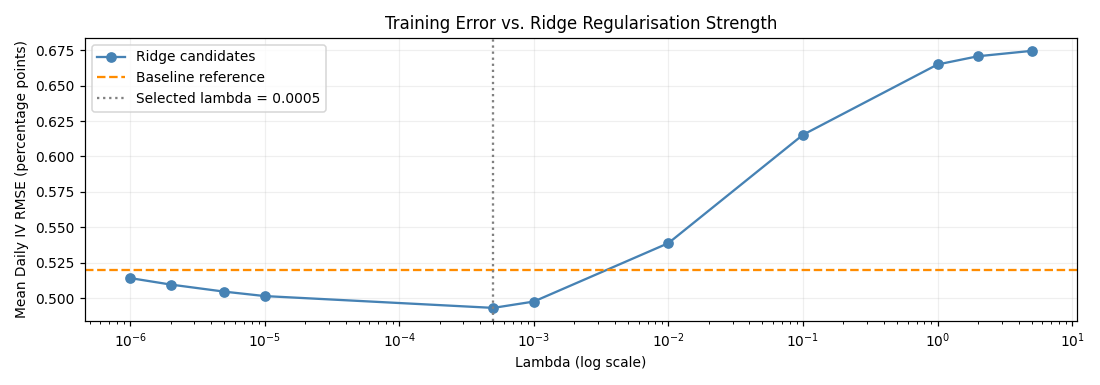

Lambda selected on training dates: 0.0005


,lambda_value,eligible,mean_train_daily_iv_rmse_pp
10,0.000001,True,0.514096
9,0.000002,True,0.509520
8,0.000005,True,0.504521
7,0.000010,True,0.501385
6,0.000500,True,0.493025
5,0.001000,True,0.497505
4,0.010000,True,0.538780
3,0.100000,True,0.615321
2,1.000000,True,0.665022
1,2.000000,True,0.670840


In [36]:
baseline_scores = daily_iv_scores(train_baseline)
baseline_train_rmse = (
    baseline_scores["rmse_iv_pp"].mean()
    if baseline_scores["n_invalid"].eq(0).all() else np.nan
)
export("baseline_train_reference.csv", pd.DataFrame({score_column: [baseline_train_rmse]}))

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(
    lambda_scores["lambda_value"], lambda_scores[score_column],
    color="steelblue", linewidth=1.5, marker="o", label="Ridge candidates"
)
if np.isfinite(baseline_train_rmse):
    ax.axhline(baseline_train_rmse, color="darkorange", linestyle="--", label="Baseline reference")
ax.axvline(selected_lambda, color="grey", linestyle=":", label=f"Selected lambda = {selected_lambda:g}")
for _, score in lambda_scores.loc[~lambda_scores["eligible"]].iterrows():
    ax.annotate("ineligible", (score["lambda_value"], 0), rotation=90)

ax.set_xscale("log")
ax.set_xlabel("Lambda (log scale)")
ax.set_ylabel("Mean Daily IV RMSE (percentage points)")
ax.set_title("Training Error vs. Ridge Regularisation Strength")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Lambda selected on training dates: {selected_lambda:g}")
display(lambda_scores[["lambda_value", "eligible", score_column]])

# IV. Test Calibration and Evaluation

The first test-date ridge fit starts from the last successful fit for the selected lambda in training. The summary tables report test dates only. Plots that originally covered the full sample show both training and test dates, with the split marked on time-series fit and parameter plots. Both models fit each test day's quotes and are scored on that day's quotes.

In [37]:
baseline, baseline_attempts = fit_baseline_path(test_days)
ridge, attempts, _ = fit_path(
    selected_lambda, test_days, frozen_scales, train_references[selected_lambda]
)
ridge_attempts = pd.DataFrame(attempts)
ridge_attempts["split"] = ridge_attempts["pricedate"].map(split_of)

assert baseline["pricedate"].tolist() == test_days
assert ridge["pricedate"].tolist() == test_days
assert ridge["lambda_value"].eq(selected_lambda).all()

test_sample = sample.loc[sample["pricedate"].isin(test_days)]
export("baseline_parameters.csv", baseline)
export("baseline_attempts.csv", baseline_attempts)
display(ridge)

,pricedate,lambda_value,fit_status,n_observations,n_attempts,n_eligible,n_numerical_exceptions,reference_date,reference_gap_days,selected_start_id,a,b,rho,m,s,q_v,q_b,q_r,q_m,q_ell,data_mse,unweighted_penalty,penalty,total_objective,raw_minimum_variance,split
0,2026-04-17,0.0005,available,190,30,30,0,2026-04-16,1,22,-0.119354,0.236045,0.080838,0.260787,0.548586,0.009713,0.236045,0.081015,0.260787,-0.600410,1.298647e-06,3.499772e-05,1.749886e-08,1.316146e-06,0.009713,test
1,2026-04-20,0.0005,available,191,30,29,1,2026-04-17,3,3,-0.119864,0.237661,0.080800,0.260712,0.548541,0.010076,0.237661,0.080976,0.260712,-0.600494,1.304412e-06,2.090454e-06,1.045227e-09,1.305457e-06,0.010076,test
2,2026-04-21,0.0005,available,192,30,30,0,2026-04-20,1,8,-0.120188,0.238653,0.080114,0.264563,0.548456,0.010282,0.238653,0.080286,0.264563,-0.600648,1.445518e-06,5.113067e-05,2.556533e-08,1.471083e-06,0.010282,test
3,2026-04-22,0.0005,available,191,30,29,1,2026-04-21,1,20,-0.119916,0.237072,0.080489,0.262703,0.548472,0.009689,0.237072,0.080663,0.262703,-0.600619,1.255282e-06,1.254842e-05,6.274209e-09,1.261557e-06,0.009689,test
4,2026-04-23,0.0005,available,191,30,30,0,2026-04-22,1,2,-0.119341,0.236310,0.080668,0.262057,0.548502,0.009854,0.236310,0.080844,0.262057,-0.600564,1.422739e-06,4.134619e-06,2.067309e-09,1.424806e-06,0.009854,test
5,2026-04-24,0.0005,available,191,30,30,0,2026-04-23,1,14,-0.118381,0.234959,0.080972,0.261016,0.548558,0.010084,0.234959,0.081150,0.261016,-0.600462,1.276018e-06,1.128970e-05,5.644848e-09,1.281663e-06,0.010084,test
6,2026-04-27,0.0005,available,190,30,30,0,2026-04-24,3,18,-0.117788,0.233683,0.081269,0.259756,0.548592,0.009984,0.233683,0.081449,0.259756,-0.600400,1.205275e-06,8.431164e-06,4.215582e-09,1.209491e-06,0.009984,test
7,2026-04-28,0.0005,available,191,30,30,0,2026-04-27,1,26,-0.117282,0.232492,0.081433,0.259401,0.548601,0.009840,0.232492,0.081614,0.259401,-0.600384,1.320494e-06,2.587886e-06,1.293943e-09,1.321788e-06,0.009840,test
8,2026-04-29,0.0005,available,191,30,30,0,2026-04-28,1,7,-0.117296,0.232135,0.081208,0.260640,0.548585,0.009629,0.232135,0.081387,0.260640,-0.600413,1.165711e-06,5.212952e-06,2.606476e-09,1.168317e-06,0.009629,test
9,2026-04-30,0.0005,available,190,30,30,0,2026-04-29,1,18,-0.117078,0.230989,0.081904,0.256697,0.548645,0.009227,0.230989,0.082088,0.256697,-0.600304,1.095985e-06,5.289438e-05,2.644719e-08,1.122433e-06,0.009227,test


## 1. Baseline vs. Ridge Penalised SVI

In [38]:
# Calculate error statistics for a set of residuals.
def error_stats(values):
    values = np.asarray(values, dtype=float)
    valid = values[np.isfinite(values)]
    stats = {
        "n_expected": len(values),
        "n_valid": len(valid),
        "n_invalid": len(values) - len(valid),
        "mse": np.nan,
        "rmse": np.nan,
        "mae": np.nan,
        "bias": np.nan,
        "max_abs": np.nan,
        "median": np.nan,
        "sample_sd": np.nan,
        "q95_abs": np.nan,
    }
    if len(valid) == 0:
        return stats
    absolute_errors = np.abs(valid)
    mse = np.mean(valid * valid)
    stats["mse"] = float(mse)
    stats["rmse"] = float(np.sqrt(mse))
    stats["mae"] = float(np.mean(absolute_errors))
    stats["bias"] = float(np.mean(valid))
    stats["max_abs"] = float(np.max(absolute_errors))
    stats["median"] = float(np.median(valid))
    stats["q95_abs"] = float(np.quantile(absolute_errors, 0.95))
    if len(valid) > 1:
        stats["sample_sd"] = float(np.std(valid, ddof=1))
    return stats


In [39]:
# Calculate daily errors and an equal-weighted test summary.
def residual_tables(frame, column):
    metrics = ["mse", "rmse", "mae", "bias", "max_abs", "median", "sample_sd", "q95_abs"]
    daily = pd.DataFrame([
        {"pricedate": date, "period": "test", **error_stats(group[column])}
        for date, group in frame.groupby("pricedate", sort=True)
    ])
    summary = {
        "period": "test",
        "aggregation": "mean_daily_metrics",
        "n_dates_expected": len(daily),
        "n_dates_with_values": int((daily["n_valid"] > 0).sum()),
        "n_expected": int(daily["n_expected"].sum()),
        "n_valid": int(daily["n_valid"].sum()),
        "n_invalid": int(daily["n_invalid"].sum()),
        **daily[metrics].mean().to_dict(),
    }
    return daily, pd.DataFrame([summary])

In [40]:
# Calculate fitted values and residuals for both models.
states = {
    "baseline": baseline,
    "ridge": ridge,
}
plot_states = {
    "baseline": pd.concat([train_baseline, baseline], ignore_index=True),
    "ridge": pd.concat([train_paths[selected_lambda], ridge], ignore_index=True),
}
quote_frames = []
for model, path in plot_states.items():
    parameters_by_date = path.set_index("pricedate")
    for date in path['pricedate']:
        daily = daily_inputs[date]
        state = parameters_by_date.loc[date]
        if state["fit_status"] == "available":
            parameters = state[RAW].to_numpy(dtype=float)
            w_model = svi(daily["k"].to_numpy(), parameters)
        else:
            w_model = np.full(len(daily), np.nan)
        iv_model = implied_volatility(
            w_model,
            daily["T"].to_numpy()
        )
        residual_w = w_model - daily["w_market"].to_numpy()
        residual_iv_pp = 100 * (
            iv_model - daily["iv_decimal"].to_numpy()
        )
        frame = daily.copy()
        frame["model"] = model
        frame["lambda_value"] = state["lambda_value"]
        frame["split"] = split_of[date]
        frame["fit_status"] = state["fit_status"]
        frame["w_model"] = w_model
        frame["iv_model_decimal"] = iv_model
        frame["residual_w"] = residual_w
        frame["residual_iv_pp"] = residual_iv_pp

        # Classify quotes by absolute log-moneyness.
        absolute_k = frame["k"].abs()
        frame["segment"] = np.select(
            [absolute_k <= 0.05, absolute_k <= 0.15],
            ["central", "intermediate"],
            default="outer"
        )
        quote_frames.append(frame)
plot_quote_results = pd.concat(quote_frames, ignore_index=True)

In [41]:
# Identify quotes valid under both baseline and ridge.
for column in ["residual_w", "residual_iv_pp"]:
    wide = plot_quote_results.pivot(
        index="source_record",
        columns="model",
        values=column
    )
    common = (
        np.isfinite(wide["baseline"])
        & np.isfinite(wide["ridge"])
    )
    plot_quote_results["common_" + column] = (
        plot_quote_results["source_record"].map(common)
    )
quote_results = plot_quote_results.loc[plot_quote_results["split"].eq("test")].copy()
export("fitted_quotes.csv", quote_results)

In [42]:

# Calculate daily and mean daily calibration errors for both models and samples.
calibration_days = []
calibration_periods = []
measures = [
    ("total_variance", "residual_w", "total implied variance"),
    ("iv", "residual_iv_pp", "IV percentage points"),
]
for model, frame in quote_results.groupby("model", sort=False):
    for sample_name in ["own", "common"]:
        for measure, column, unit in measures:
            selected = frame.copy()
            if sample_name == "common":
                selected.loc[~selected["common_" + column], column] = np.nan
            daily, summary = residual_tables(selected, column)
            for table in [daily, summary]:
                table["model"] = model
                table["sample"] = sample_name
                table["measure"] = measure
                table["residual_unit"] = unit
            calibration_days.append(daily)
            calibration_periods.append(summary)
calibration_daily = pd.concat(calibration_days, ignore_index=True)
calibration_summary = pd.concat(calibration_periods, ignore_index=True)
export("calibration_daily.csv", calibration_daily)
export("calibration_summary.csv", calibration_summary)




In [43]:
# Display mean daily IV errors on the common quote sample.
display_rows = calibration_summary[
    (calibration_summary["sample"] == "common")
    & (calibration_summary["measure"] == "iv")
]
display(display_rows[["model", "period", "n_valid", "rmse", "mae", "bias"]])

,model,period,n_valid,rmse,mae,bias
3,baseline,test,5974,0.361324,0.292424,0.008826
7,ridge,test,5974,0.380499,0.295518,0.004066


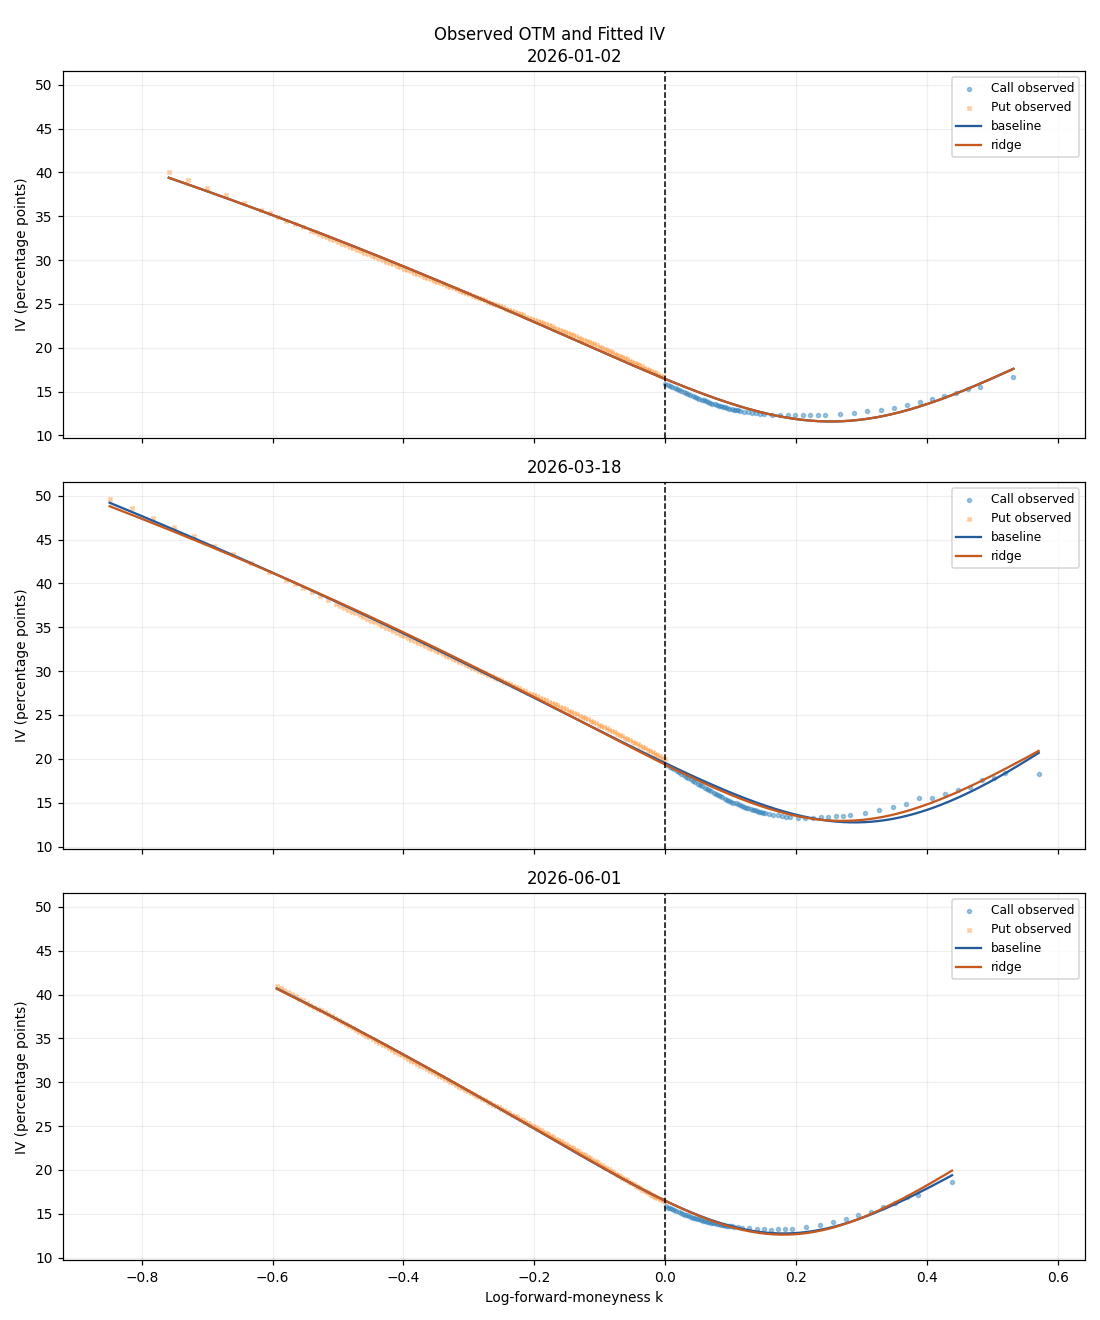

In [44]:
# Use the original representative dates and mark the current split.
representative_dates = pd.to_datetime(["2026-01-02", "2026-03-18", "2026-06-01"])

def mark_splits(ax):
    ax.axvline(test_days[0], color="grey", linestyle=":", linewidth=0.8)

# Evaluate both SVI fits on 401 log-moneyness points for each representative date.
representative_curves = []
for date in representative_dates:
    daily = daily_inputs[date]
    grid = np.linspace(daily["k"].min(), daily["k"].max(), 401)
    maturity = float(daily["T"].iloc[0])
    for model, path in plot_states.items():
        state = path.set_index("pricedate").loc[date]
        if state["fit_status"] != "available":
            continue
        variance = svi(grid, state[RAW].to_numpy(float))
        volatility = implied_volatility(variance, np.full(len(grid), maturity))
        representative_curves.append(pd.DataFrame({
            "pricedate": date, "model": model, "k": grid,
            "w": variance, "iv_pp": 100 * volatility
        }))
representative_curves = pd.concat(representative_curves, ignore_index=True)
export("representative_plot_values.csv", representative_curves)

# Compare observed OTM IV with fitted baseline and ridge curves
fig, axes = plt.subplots(3, 1, figsize=(10, 12), sharex=True, sharey=True)

for ax, date in zip(axes, representative_dates):
    observed = sample[sample["pricedate"] == date]

    for side, marker in [("Call", "o"), ("Put", "x")]:
        group = observed[observed["option_type"] == side]

        ax.scatter(
            group["k"], 100 * group["iv_decimal"],
            s=7, alpha=0.4, marker=marker,
            label=side + " observed"
        )

    for model in ["baseline", "ridge"]:
        curve = representative_curves[
            (representative_curves["pricedate"] == date) &
            (representative_curves["model"] == model)
        ]

        ax.plot(
            curve["k"], curve["iv_pp"],
            color=COLORS[model], label=model
        )

    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set(
        title=date.strftime("%Y-%m-%d"),
        ylabel="IV (percentage points)"
    )
    ax.legend(fontsize=8)

axes[-1].set_xlabel("Log-forward-moneyness k")

fig.suptitle("Observed OTM and Fitted IV")
plt.tight_layout()
save_figure(fig, "02_representative_iv")

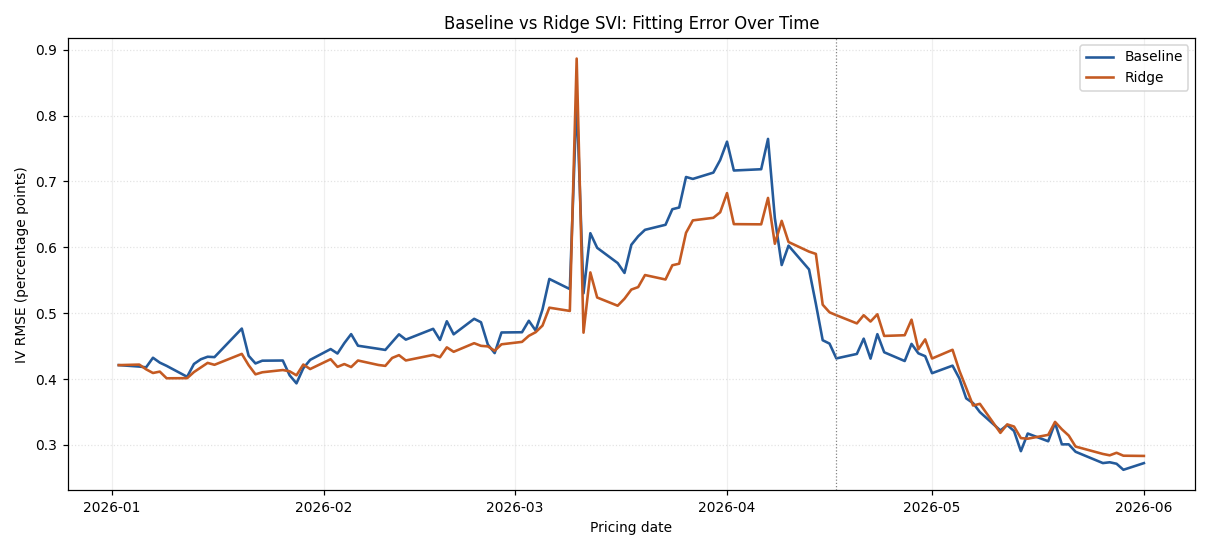

In [45]:
# Compare baseline and ridge SVI fitting errors across dates

plot_ridge = plot_states["ridge"]
plot_baseline = plot_states["baseline"]

ridge_selected = plot_ridge.loc[
    np.isclose(plot_ridge["lambda_value"], selected_lambda)
    & plot_ridge["fit_status"].eq("available")
].copy()

baseline_selected = plot_baseline.loc[
    plot_baseline["fit_status"].eq("available")
].copy()

# Align available fits from both models on the same dates
fits = baseline_selected.merge(
    ridge_selected,
    on="pricedate",
    suffixes=("_baseline", "_ridge"),
    how="inner",
    validate="one_to_one"
).sort_values("pricedate")

# Calculate daily IV RMSE for both models
error_rows = []

for _, row in fits.iterrows():
    date = row["pricedate"]
    observed = sample.loc[sample["pricedate"] == date]

    if observed.empty:
        continue

    k = observed["k"].to_numpy(float)
    market_iv = observed["iv_decimal"].to_numpy(float)
    T = daily_inputs[date]["T"].iloc[0]

    errors = {"pricedate": date}

    for model in ["baseline", "ridge"]:
        params = np.array([
            row[f"{p}_{model}"] for p in RAW
        ], dtype=float)

        w = svi(k, params)

        # Do not treat negative fitted variance as valid IV
        if (
            not np.isfinite(T) or T <= 0
            or not np.isfinite(w).all()
            or (w < 0).any()
            or not np.isfinite(market_iv).all()
        ):
            errors[model] = np.nan
            continue

        fitted_iv = np.sqrt(w / T)

        errors[model] = (
            100 * np.sqrt(np.mean((fitted_iv - market_iv) ** 2))
        )

    error_rows.append(errors)

error_df = pd.DataFrame(error_rows).sort_values("pricedate")

# Plot fitting errors over time
fig, ax = plt.subplots(figsize=(11, 5))

for model in ["baseline", "ridge"]:
    ax.plot(
        error_df["pricedate"],
        error_df[model],
        color=COLORS[model],
        linewidth=1.7,
        label=model.capitalize()
    )

ax.set_ylabel("IV RMSE (percentage points)")
ax.set_xlabel("Pricing date")
ax.set_title("Baseline vs Ridge SVI: Fitting Error Over Time")

mark_splits(ax)

ax.legend()
ax.grid(axis="y", linestyle=":", alpha=0.35)

fig.tight_layout()
save_figure(fig, "09_fitting_error_over_time")

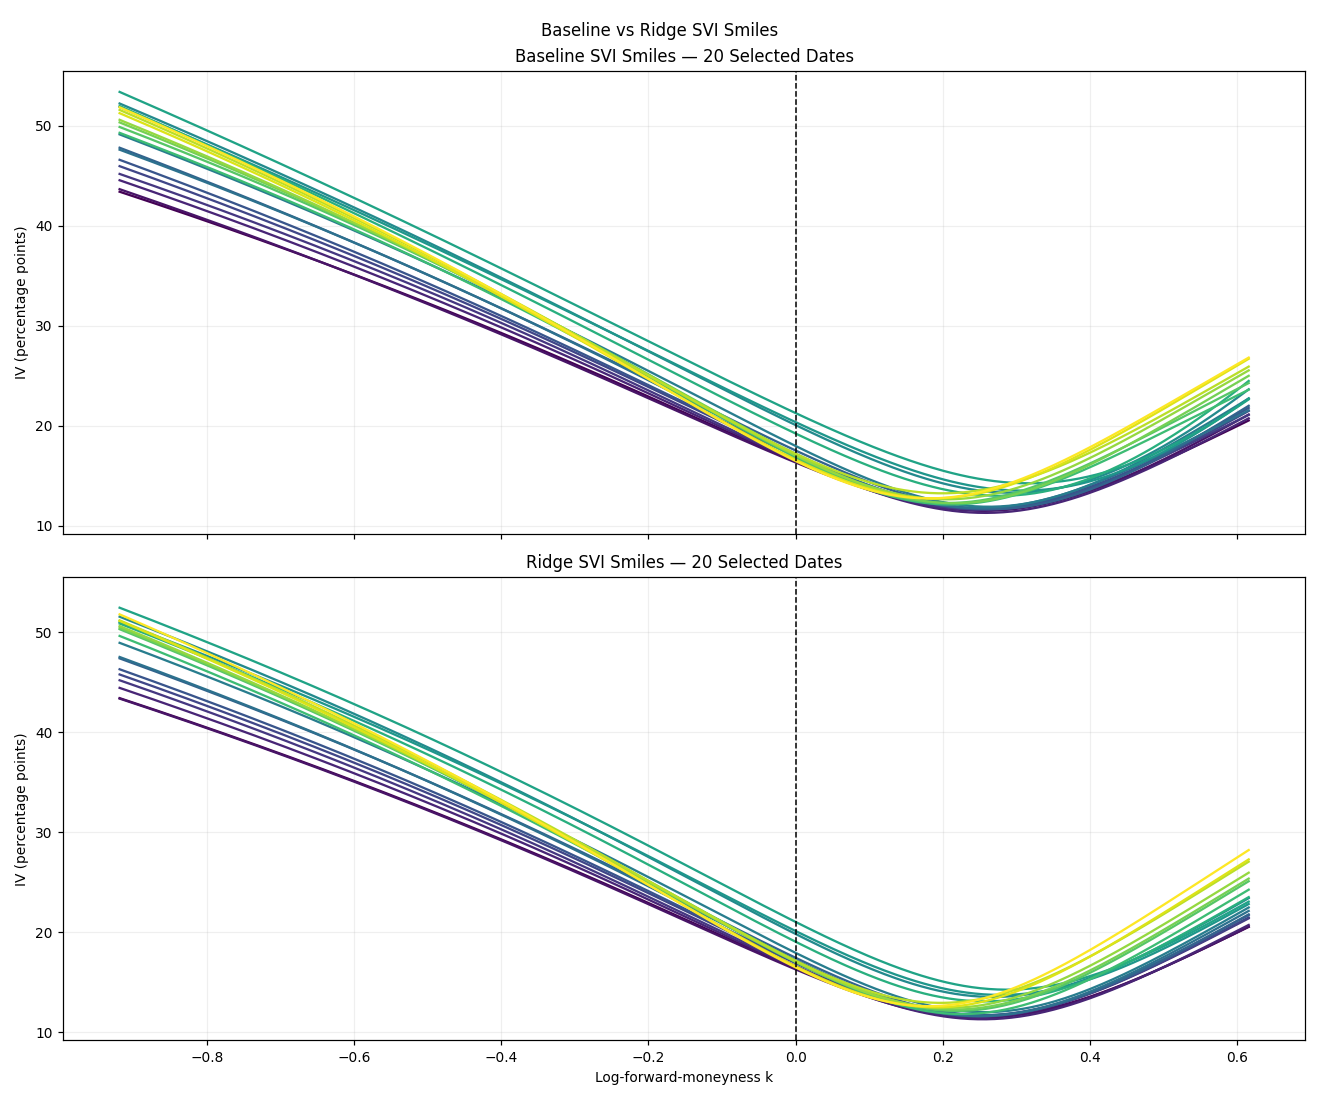

In [46]:
# Compare 20 baseline and ridge SVI smiles across dates
selected_dates = [
    days[i] for i in np.linspace(0, len(days)-1, 20, dtype=int)
]

ridge_selected = plot_ridge.loc[
    np.isclose(plot_ridge["lambda_value"], selected_lambda)
    & plot_ridge["fit_status"].eq("available")
]

baseline_selected = plot_baseline.loc[
    plot_baseline["fit_status"].eq("available")
]

fig, axes = plt.subplots(
    2, 1, figsize=(12, 10), sharex=True, sharey=True
)

cmap = plt.cm.viridis
k_grid = np.linspace(sample["k"].min(), sample["k"].max(), 401)

for ax, model, fits in zip(
    axes,
    ["Baseline", "Ridge"],
    [baseline_selected, ridge_selected]
):
    for i, date in enumerate(selected_dates):
        match = fits[fits["pricedate"] == date]

        if match.empty:
            continue

        row = match.iloc[0]
        T = daily_inputs[date]["T"].iloc[0]

        params = row[RAW].to_numpy(float)
        w = svi(k_grid, params)
        iv_pp = 100 * np.sqrt(np.maximum(w, 0) / T)

        ax.plot(
            k_grid, iv_pp,
            color=cmap(i / 19),
            linewidth=1.5,
            label=pd.Timestamp(date).strftime("%Y-%m-%d")
        )

    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set(
        title=f"{model} SVI Smiles — 20 Selected Dates",
        ylabel="IV (percentage points)"
    )
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Log-forward-moneyness k")

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    fontsize=8,
    bbox_to_anchor=(1.02, 0.5),
    loc="center left"
)

fig.suptitle("Baseline vs Ridge SVI Smiles")
plt.tight_layout(rect=[0, 0, 0.85, 0.97])

save_figure(fig, "baseline_vs_ridge_smiles")

## 2. Segmented Baseline vs. Ridge Penalised SVI

In [47]:
# Calculate segmented IV errors using equal-weighted daily averages.
def segmented_iv_errors(quotes, dates, period):
    segment_rows = []
    for model, frame in quotes.groupby("model", sort=False):
        for sample_name in ["own", "common"]:
            selected = frame.copy()
            if sample_name == "common":
                selected.loc[~selected["common_residual_iv_pp"], "residual_iv_pp"] = np.nan
            for side in ["Call", "Put", "combined"]:
                side_frame = selected if side == "combined" else selected[selected["option_type"] == side]
                for segment in ["central", "intermediate", "outer"]:
                    group = side_frame[side_frame["segment"] == segment]
                    daily_rows = []
                    for date in dates:
                        day = group[group["pricedate"] == date]
                        stats = error_stats(day["residual_iv_pp"])
                        row = {
                            "model": model, "sample": sample_name,
                            "side": side, "segment": segment,
                            "granularity": "daily", "pricedate": date,
                            "period": period, **stats
                        }
                        daily_rows.append(row)
                    segment_rows.extend(daily_rows)

                    daily = pd.DataFrame(daily_rows)
                    metrics = ["mse", "rmse", "mae", "bias", "max_abs", "median", "sample_sd", "q95_abs"]
                    counts = {name: int(daily[name].sum()) for name in ["n_expected", "n_valid", "n_invalid"]}
                    segment_rows.append({
                        "model": model, "sample": sample_name,
                        "side": side, "segment": segment,
                        "granularity": "period", "pricedate": pd.NaT,
                        "period": period, **counts, **daily[metrics].mean().to_dict(),
                    })
    return pd.DataFrame(segment_rows)


segments = segmented_iv_errors(quote_results, test_days, "test")
export("segmented_iv_residuals.csv", segments)
display(segments)

,model,sample,side,segment,granularity,pricedate,period,n_expected,n_valid,n_invalid,mse,rmse,mae,bias,max_abs,median,sample_sd,q95_abs
0,baseline,own,Call,central,daily,2026-04-17,test,15,15,0,0.389964,0.624471,0.618909,0.618909,0.737532,0.629566,0.086082,0.729623
1,baseline,own,Call,central,daily,2026-04-20,test,15,15,0,0.410657,0.640825,0.634586,0.634586,0.760349,0.645402,0.092339,0.749986
2,baseline,own,Call,central,daily,2026-04-21,test,15,15,0,0.400068,0.632510,0.624720,0.624720,0.766958,0.633714,0.102433,0.756971
3,baseline,own,Call,central,daily,2026-04-22,test,15,15,0,0.414443,0.643772,0.638392,0.638392,0.751810,0.654640,0.085973,0.746264
4,baseline,own,Call,central,daily,2026-04-23,test,15,15,0,0.458166,0.676880,0.670272,0.670272,0.807160,0.676041,0.097662,0.795022
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1147,ridge,common,combined,outer,daily,2026-05-27,test,112,112,0,0.083084,0.288243,0.208061,-0.038638,1.213170,0.011611,0.286926,0.723678
1148,ridge,common,combined,outer,daily,2026-05-28,test,112,112,0,0.085998,0.293254,0.202809,-0.039741,1.261266,0.012808,0.291854,0.759785
1149,ridge,common,combined,outer,daily,2026-05-29,test,109,109,0,0.079035,0.281131,0.197118,-0.046467,1.231493,-0.015140,0.278545,0.685482
1150,ridge,common,combined,outer,daily,2026-06-01,test,112,112,0,0.072589,0.269424,0.196098,-0.046911,1.322974,-0.025373,0.266501,0.598816


## 3. Parameter and Functional Stability

Measure stability by sample variance across the test dates on which both models have a fit. For each fitted SVI parameter, use its raw values across those dates. For the fitted curves, calculate total volatility $\sqrt{w(k)}$ in decimal units on a common log-moneyness grid within the observed range of every test date. Compute the variance across dates at each grid point and take the mean over grid points valid in both models.

In [48]:
# Use log-moneyness covered by every test date.
support = test_sample.groupby("pricedate")["k"].agg(["min", "max"])
common_lower = support["min"].max()
common_upper = support["max"].min()
common_grid = (
    np.linspace(common_lower, common_upper, 201)
    if common_lower < common_upper
    else np.array([common_lower]) if common_lower == common_upper else np.array([])
)

parameter_paths = {
    model: path.loc[path["fit_status"].eq("available")].set_index("pricedate")[RAW]
    for model, path in states.items()
}
stability_dates = pd.Index(test_days)
for parameters in parameter_paths.values():
    stability_dates = stability_dates.intersection(parameters.index)

In [49]:
parameter_variances = {}
total_volatility_paths = {}
for model, parameters in parameter_paths.items():
    parameters = parameters.loc[stability_dates]
    parameter_variances[model] = parameters.var(ddof=1)
    total_variance = np.array([
        svi(common_grid, theta) for theta in parameters.to_numpy(dtype=float)
    ]).reshape(len(stability_dates), len(common_grid))
    valid = np.isfinite(total_variance) & (total_variance >= 0)
    total_volatility_paths[model] = np.sqrt(np.where(valid, total_variance, np.nan))

In [50]:
common_valid = np.full(len(common_grid), len(stability_dates) >= 2)
for volatility in total_volatility_paths.values():
    common_valid &= np.isfinite(volatility).all(axis=0)

pointwise_variances = pd.DataFrame({
    model: pd.DataFrame(volatility[:, common_valid]).var(ddof=1).to_numpy()
    for model, volatility in total_volatility_paths.items()
}, index=pd.Index(common_grid[common_valid], name="k"))

stability_variances = pd.DataFrame(parameter_variances)
stability_variances.loc["Mean pointwise total-volatility variance"] = pointwise_variances.mean()
stability_variances.index.name = "quantity"

export("stability_variances.csv", stability_variances.reset_index())
export("total_volatility_variance_by_k.csv", pointwise_variances.reset_index())

In [51]:
print(f"Matched test dates: {len(stability_dates)} of {len(test_days)}")
print(f"Common grid points used: {common_valid.sum()} of {len(common_grid)}")
display(stability_variances)

Matched test dates: 31 of 31
Common grid points used: 201 of 201


,baseline,ridge
quantity,,
a,0.000328,6.261857e-06
b,0.000242,2.805031e-05
rho,0.002208,3.875906e-06
m,0.000669,1.370672e-04
s,0.002670,1.326547e-07
Mean pointwise total-volatility variance,0.000032,3.181170e-05


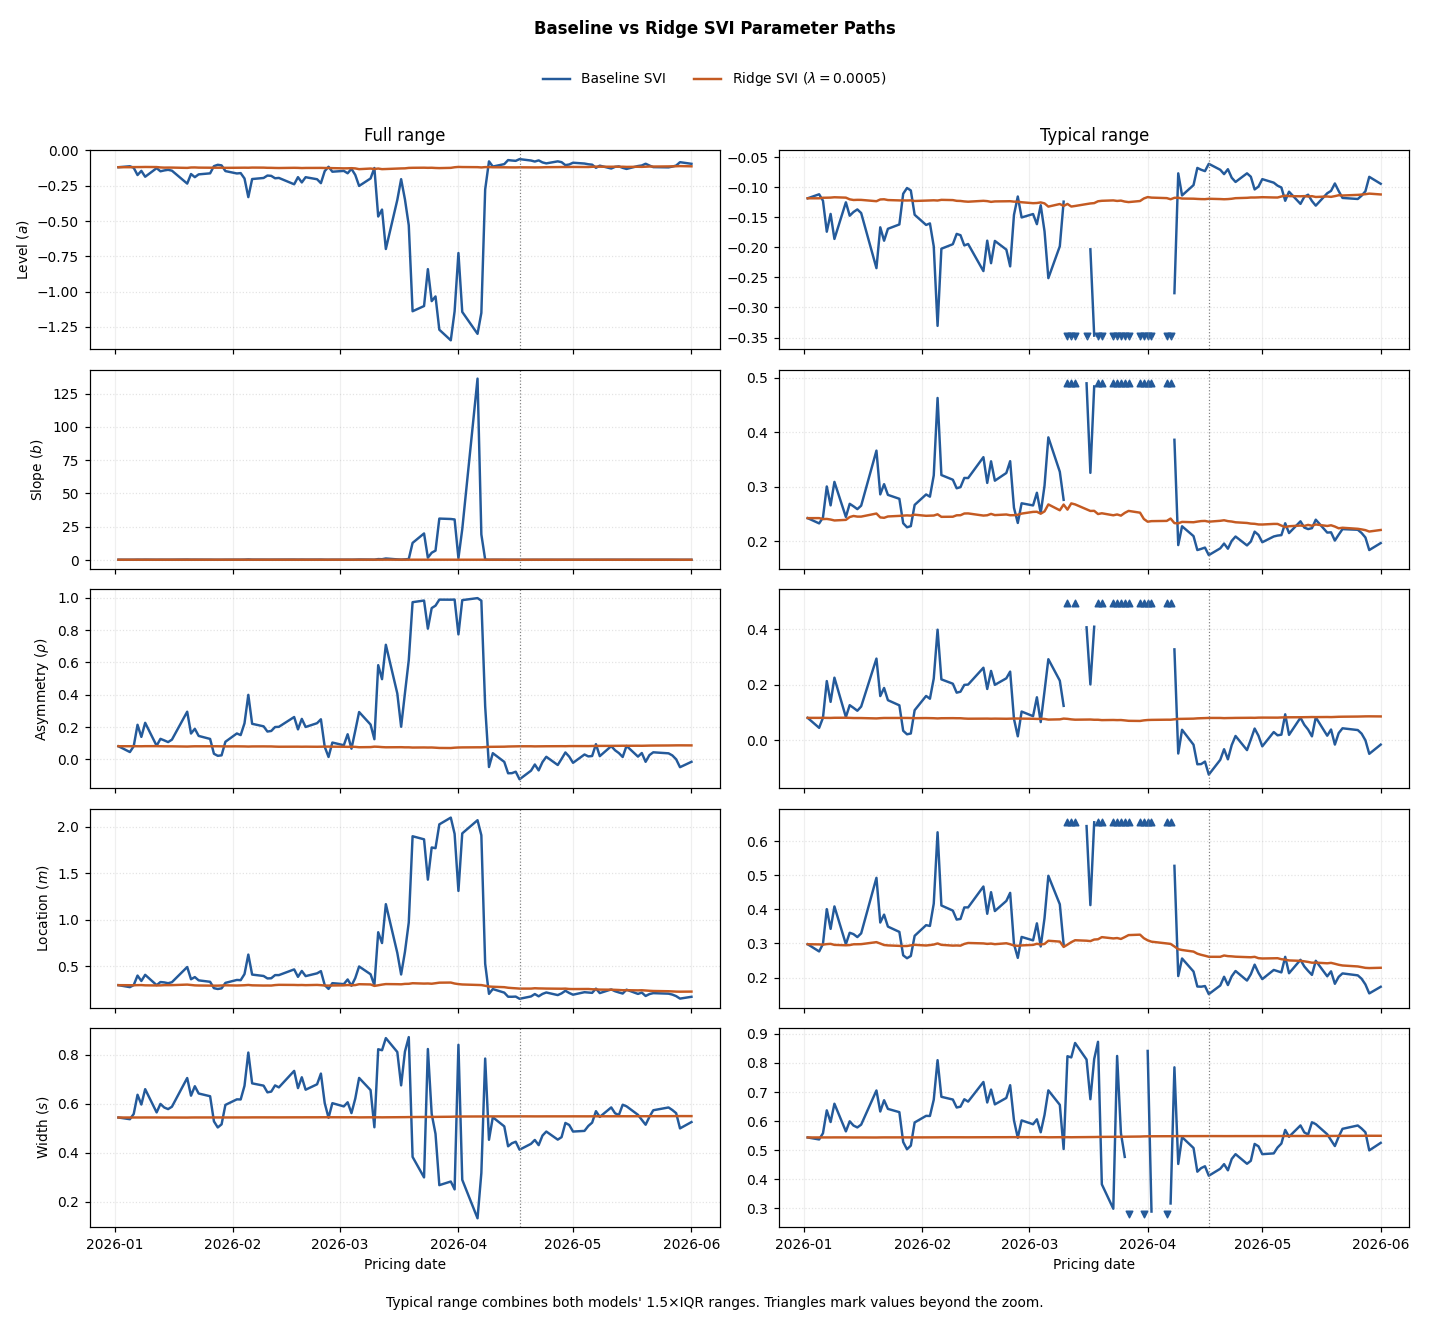

In [52]:
# Align the two parameter paths and keep the full pricing-date axis.
param_labels = {
    "a": r"Level ($a$)",
    "b": r"Slope ($b$)",
    "rho": r"Asymmetry ($\rho$)",
    "m": r"Location ($m$)",
    "s": r"Width ($s$)",
}

plot_data = pd.DataFrame({"pricedate": days})
for model, path in plot_states.items():
    available = path.loc[path["fit_status"].eq("available"), ["pricedate"] + RAW]
    columns = {param: f"{param}_{model}" for param in RAW}
    plot_data = plot_data.merge(available.rename(columns=columns), on="pricedate", validate="one_to_one", how="left")

fig, axes = plt.subplots(len(RAW), 2, figsize=(13, 12), sharex=True)
axes[0, 0].set_title("Full range")
axes[0, 1].set_title("Typical range")
model_labels = {"baseline": "Baseline SVI", "ridge": fr"Ridge SVI ($\lambda={selected_lambda:g}$)"}
dates = plot_data["pricedate"]

for param, (full_ax, zoom_ax) in zip(RAW, axes):
    series = {model: plot_data[f"{param}_{model}"] for model in model_labels}
    values_by_model = pd.DataFrame(series)
    quartiles = values_by_model.quantile([0.25, 0.75])
    q1, q3 = quartiles.loc[0.25], quartiles.loc[0.75]
    iqr = q3 - q1
    in_range = values_by_model.ge(q1 - 1.5 * iqr) & values_by_model.le(q3 + 1.5 * iqr)
    central = values_by_model.where(in_range)
    lower, upper = central.min().min(), central.max().max()
    span = upper - lower

    for model, values in series.items():
        color = COLORS[model]
        full_ax.plot(dates, values, color=color, linewidth=1.6, label=model_labels[model])
        zoom_ax.plot(dates, values.where(values.between(lower, upper)), color=color, linewidth=1.6)
        for mask, level, marker in (
            (values.lt(lower), lower, "v"),
            (values.gt(upper), upper, "^"),
        ):
            zoom_ax.scatter(dates[mask], np.full(mask.sum(), level), marker=marker, color=color, s=18)

    if span > 0:
        zoom_ax.set_ylim(lower - 0.08 * span, upper + 0.08 * span)
    full_ax.set_ylabel(param_labels[param])
    for ax in (full_ax, zoom_ax):
        mark_splits(ax)
        ax.grid(axis="y", linestyle=":", alpha=0.35)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.956), ncol=2, frameon=False)
fig.suptitle("Baseline vs Ridge SVI Parameter Paths", y=0.985, fontweight="bold")
for ax in axes[-1]:
    ax.set_xlabel("Pricing date")
fig.text(
    0.5, 0.01,
    "Typical range combines both models' 1.5×IQR ranges. Triangles mark values beyond the zoom.",
    ha="center",
)
fig.tight_layout(rect=(0, 0.025, 1, 0.94))
fig.savefig(FIGURES / "08_parameter_paths_baseline_vs_ridge.png", dpi=200, bbox_inches="tight")
display(fig)
plt.close(fig)


## 4. Call–Put IV Consistency

In [53]:
# Match calls and puts by date, expiry, and strike.
pair_keys = ["pricedate", "Expiry", "strike"]
call_side = options[options["option_type"] == "Call"][pair_keys + ["iv_decimal", "source_record"]].copy()
put_side = options[options["option_type"] == "Put"][pair_keys + ["iv_decimal", "source_record"]].copy()
call_side = call_side.rename(columns={
    "iv_decimal": "iv_call_decimal",
    "source_record": "call_source_record"
})
put_side = put_side.rename(columns={
    "iv_decimal": "iv_put_decimal",
    "source_record": "put_source_record"
})
plot_pair_ledger = call_side.merge(
    put_side, on=pair_keys, how="outer",
    validate="one_to_one", indicator="source_key_status"
)
plot_pair_ledger["missing_call_iv"] = plot_pair_ledger["iv_call_decimal"].isna()
plot_pair_ledger["missing_put_iv"] = plot_pair_ledger["iv_put_decimal"].isna()
plot_pair_ledger["complete_pair"] = ~plot_pair_ledger["missing_call_iv"] & ~plot_pair_ledger["missing_put_iv"]
plot_pair_ledger["split"] = plot_pair_ledger["pricedate"].map(split_of)
pair_ledger = plot_pair_ledger.loc[plot_pair_ledger["split"].eq("test")].copy()

In [54]:
# Calculate IV differences for complete call-put pairs.
plot_pairs = plot_pair_ledger.loc[plot_pair_ledger["complete_pair"]].copy()
plot_pairs = plot_pairs.merge(
    forward_audit[["pricedate", "F"]],
    on="pricedate", validate="many_to_one"
)
plot_pairs["k"] = np.log(plot_pairs["strike"] / plot_pairs["F"])
plot_pairs["delta_iv_pp"] = 100 * (plot_pairs["iv_call_decimal"] - plot_pairs["iv_put_decimal"])

pairs = plot_pairs.loc[plot_pairs["split"].eq("test")].copy()

# Calculate daily call-put IV error statistics.
pair_daily, pair_summary = residual_tables(pairs, "delta_iv_pp")

In [55]:
# Summarize coverage for matched test-date quotes.
missing_call = pair_ledger["missing_call_iv"]
missing_put = pair_ledger["missing_put_iv"]
coverage = pd.DataFrame([{
    "period": "test",
    "n_keys": len(pair_ledger),
    "complete_pairs": int(pair_ledger["complete_pair"].sum()),
    "missing_call_iv": int(missing_call.sum()),
    "missing_put_iv": int(missing_put.sum()),
    "unmatched_nonmissing_call": int((~missing_call & missing_put).sum()),
    "unmatched_nonmissing_put": int((missing_call & ~missing_put).sum()),
}])

# Export call-put consistency results.
export("call_put_pairs.csv", pairs)
export("call_put_daily.csv", pair_daily)
export("call_put_summary.csv", pair_summary)
export("call_put_coverage_summary.csv", coverage)

display(pd.DataFrame(pair_daily))
display(pd.DataFrame(pair_summary))

,pricedate,period,n_expected,n_valid,n_invalid,mse,rmse,mae,bias,max_abs,median,sample_sd,q95_abs
0,2026-04-17,test,195,195,0,11.312370,3.363387,2.137008,-2.137008,24.157349,-1.151991,2.603908,6.709913
1,2026-04-20,test,195,195,0,10.049681,3.170123,2.095539,-2.095539,17.675226,-1.115118,2.384861,6.490996
2,2026-04-21,test,195,195,0,8.655181,2.941969,1.970777,-1.970777,18.679720,-1.068863,2.189935,6.172742
3,2026-04-22,test,194,194,0,10.710718,3.272723,2.148326,-2.148326,21.772911,-1.194877,2.475277,6.541753
4,2026-04-23,test,194,194,0,10.376208,3.221212,2.194734,-2.194734,14.592314,-1.229214,2.363928,6.598691
5,2026-04-24,test,195,195,0,8.471695,2.910618,1.964475,-1.964475,15.015240,-1.078979,2.153209,6.241413
6,2026-04-27,test,194,194,0,8.324239,2.885176,2.007168,-2.007168,13.224430,-1.124091,2.077925,6.127612
7,2026-04-28,test,192,192,0,12.198759,3.492672,2.404542,-2.404542,20.215046,-1.363676,2.539790,7.112564
8,2026-04-29,test,195,195,0,7.722221,2.778888,1.826580,-1.826580,16.101254,-1.016862,2.099627,6.039251
9,2026-04-30,test,192,192,0,9.191446,3.031740,2.122087,-2.122087,15.373840,-1.200065,2.170884,6.085736


,period,aggregation,n_dates_expected,n_dates_with_values,n_expected,n_valid,n_invalid,mse,rmse,mae,bias,max_abs,median,sample_sd,q95_abs
0,test,mean_daily_metrics,31,31,6100,6100,0,9.912815,3.133878,2.109595,-2.109595,15.756228,-1.121833,2.321911,6.562744


In [56]:
# Examine the direction of matched call-put IV differences.
print("Total pairs:", len(pairs))
print("Call IV higher:", (pairs["delta_iv_pp"] > 0).sum())
print("Put IV higher:", (pairs["delta_iv_pp"] < 0).sum())
print("Equal IV:", (pairs["delta_iv_pp"] == 0).sum())
print("Mean difference (pp):", pairs["delta_iv_pp"].mean())
print("Median difference (pp):", pairs["delta_iv_pp"].median())

Total pairs: 6100
Call IV higher: 0
Put IV higher: 6100
Equal IV: 0
Mean difference (pp): -2.1081533675672133
Median difference (pp): -1.1186437599999988


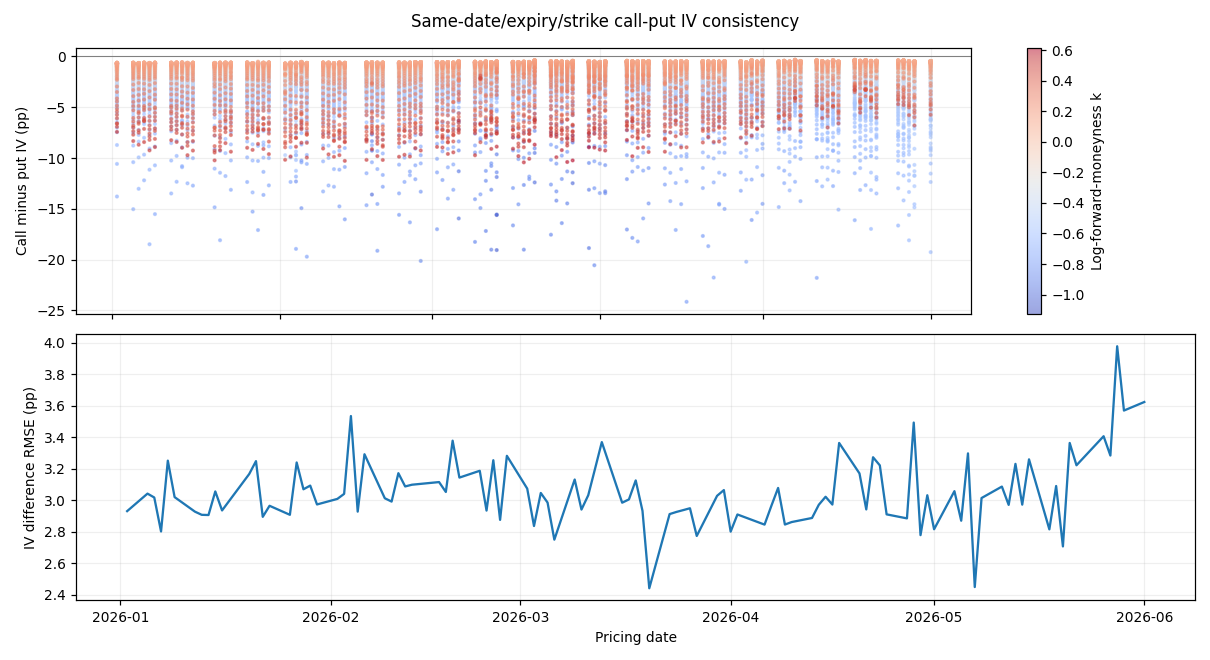

In [57]:
# Show matched call-minus-put IV differences and daily RMSE across all dates.
plot_pair_rmse = plot_pairs.groupby("pricedate")["delta_iv_pp"].agg(
    lambda values: np.sqrt(np.mean(values**2))
)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
points = axes[0].scatter(plot_pairs["pricedate"], plot_pairs["delta_iv_pp"], c=plot_pairs["k"],
                         s=3, alpha=0.5, cmap="coolwarm")
fig.colorbar(points, ax=axes[0], label="Log-forward-moneyness k")
axes[0].axhline(0, color="grey", linewidth=0.7)
axes[0].set_ylabel("Call minus put IV (pp)")
axes[1].plot(plot_pair_rmse.index, plot_pair_rmse)
axes[1].set(ylabel="IV difference RMSE (pp)", xlabel="Pricing date")
fig.suptitle("Same-date/expiry/strike call-put IV consistency")
save_figure(fig, "09_call_put_iv")

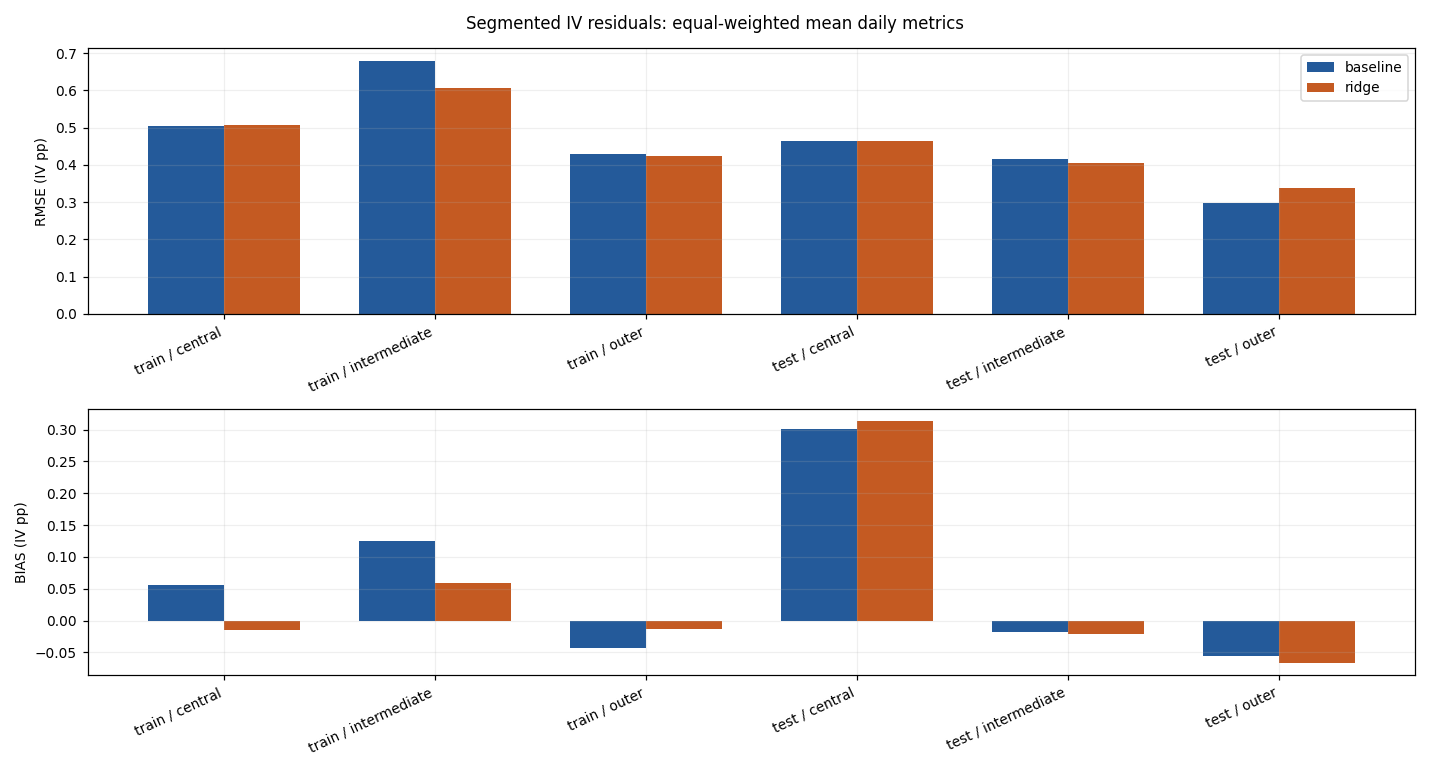

In [58]:
# Compare baseline and ridge mean-daily segmented IV errors on the common sample.
segment_periods = segments[(segments["granularity"] == "period")
                           & (segments["sample"] == "common")
                           & (segments["side"] == "combined")]

train_quote_results = plot_quote_results.loc[plot_quote_results["split"].eq("train")]
train_segments = segmented_iv_errors(train_quote_results, train_days, "train")
train_segment_periods = train_segments[
    train_segments["granularity"].eq("period")
    & train_segments["sample"].eq("common")
    & train_segments["side"].eq("combined")
]
plot_segment_periods = pd.concat([train_segment_periods, segment_periods], ignore_index=True)

labels = [(period, region) for period in ["train", "test"]
          for region in ["central", "intermediate", "outer"]]
x = np.arange(len(labels))
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
for ax, metric in zip(axes, ["rmse", "bias"]):
    for j, model in enumerate(["baseline", "ridge"]):
        group = plot_segment_periods[plot_segment_periods["model"] == model]
        values = [group[(group["period"] == period) & (group["segment"] == region)][metric].iloc[0]
                  for period, region in labels]
        ax.bar(x + (j - 0.5) * 0.36, values, width=0.36,
               label=model, color=COLORS[model])
    ax.set_xticks(x, [period + " / " + region for period, region in labels],
                  rotation=25, ha="right")
    ax.set_ylabel(metric.upper() + " (IV pp)")
axes[0].legend()
fig.suptitle("Segmented IV residuals: equal-weighted mean daily metrics")
save_figure(fig, "10_segmented_residuals")

# V. Test Results

## Error, Stability, and Calibration Tables

In [59]:
# Display the main error and stability summaries from the evaluation sections.
display(calibration_summary[(calibration_summary["sample"] == "common")
                            & (calibration_summary["measure"] == "iv")]
        [["model", "period", "n_valid", "rmse", "mae", "bias"]])
display(stability_variances)
display(pair_summary[["period", "n_valid", "rmse", "mae", "bias", "max_abs"]])
display(segment_periods[["model", "period", "segment", "n_valid", "rmse", "mae", "bias"]])

,model,period,n_valid,rmse,mae,bias
3,baseline,test,5974,0.361324,0.292424,0.008826
7,ridge,test,5974,0.380499,0.295518,0.004066


,baseline,ridge
quantity,,
a,0.000328,6.261857e-06
b,0.000242,2.805031e-05
rho,0.002208,3.875906e-06
m,0.000669,1.370672e-04
s,0.002670,1.326547e-07
Mean pointwise total-volatility variance,0.000032,3.181170e-05


,period,n_valid,rmse,mae,bias,max_abs
0,test,6100,3.133878,2.109595,-2.109595,15.756228


,model,period,segment,n_valid,rmse,mae,bias
511,baseline,test,central,929,0.464801,0.379961,0.300737
543,baseline,test,intermediate,1502,0.416838,0.392042,-0.018493
575,baseline,test,outer,3543,0.296649,0.227704,-0.056230
1087,ridge,test,central,929,0.463320,0.370936,0.313100
1119,ridge,test,intermediate,1502,0.406002,0.377116,-0.020569
1151,ridge,test,outer,3543,0.338193,0.241792,-0.066223


In [60]:
# Summarize calibration availability and optimiser outcomes.
execution_rows = []
parameter_rows = []
for model, path in states.items():
    available = path[path["fit_status"] == "available"]
    attempts = (baseline_attempts if model == "baseline" else
                ridge_attempts[ridge_attempts["lambda_value"] == selected_lambda])
    execution_rows.append({
        "model": model, "expected_dates": len(test_days), "available_dates": len(available),
        "unavailable_dates": len(test_days) - len(available), "attempts": len(attempts),
        "eligible_attempts": int(attempts["eligible"].sum()),
        "numerical_exceptions": int((attempts["outcome"] == "numerical_exception").sum()),
        "nonconverged": int((attempts["outcome"] == "nonconverged_finite_feasible").sum()),
        "selected_b_zero": int((available["b"] == 0).sum()),
        "selected_v_zero": int((available["q_v"] == 0).sum())
    })
    summary = available[RAW + ["q_v", "raw_minimum_variance"]].describe().T
    parameter_rows.append(summary.rename_axis("parameter").reset_index().assign(model=model))
execution_summary = pd.DataFrame(execution_rows)
parameter_summary = pd.concat(parameter_rows, ignore_index=True)
ridge_attempt_summary = (ridge_attempts.groupby(["lambda_value", "split", "outcome"], sort=False)
                         .size().rename("attempts").reset_index())
export("model_execution_summary.csv", execution_summary)
export("model_parameter_summary.csv", parameter_summary)
export("ridge_attempt_summary.csv", ridge_attempt_summary)
display(execution_summary)
display(parameter_summary[["model", "parameter", "count", "mean", "std", "min", "50%", "max"]])

,model,expected_dates,available_dates,unavailable_dates,attempts,eligible_attempts,numerical_exceptions,nonconverged,selected_b_zero,selected_v_zero
0,baseline,31,31,0,899,898,1,0,0,0
1,ridge,31,31,0,930,923,7,0,0,0


,model,parameter,count,mean,std,min,50%,max
0,baseline,a,31.0,-0.099724,0.018105,-0.130822,-0.100598,-0.061277
1,baseline,b,31.0,0.209548,0.015554,0.174830,0.211436,0.239712
2,baseline,rho,31.0,0.008874,0.046984,-0.123451,0.016833,0.093934
3,baseline,m,31.0,0.206237,0.025870,0.151354,0.207668,0.260595
4,baseline,s,31.0,0.519940,0.051668,0.412186,0.522828,0.596143
5,baseline,q_v,31.0,0.009789,0.000403,0.008904,0.009710,0.010550
6,baseline,raw_minimum_variance,31.0,0.009789,0.000403,0.008904,0.009710,0.010550
7,ridge,a,31.0,-0.115943,0.002502,-0.120188,-0.115629,-0.110809
8,ridge,b,31.0,0.229436,0.005296,0.218025,0.229477,0.238653
9,ridge,rho,31.0,0.083123,0.001969,0.080114,0.083159,0.086609
